In [1]:
!md dataset
!tar -xf dataset.zip -C ./dataset

A subdirectory or file dataset already exists.


^C


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import scipy.stats as stats
from itertools import combinations
from scipy.io import wavfile
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

np.random.seed(42)

# Module A

## Ex. 2

### Ex. 2.1.

In [4]:
filenames = os.listdir('./dataset')
sample_filenames = {}

for label in filenames:
    if not label == '__MACOSX':
        sample_filenames[label] = os.listdir(f'./dataset/{label}')

In [8]:
labels = list(iter(sample_filenames.keys()))
for label in labels:
    print(f"{label}: {len(sample_filenames[label])}")

backward: 1664
forward: 1557
left: 3801
right: 3778
stop: 3872
_silence_: 408
_unknown_: 635


### Ex. 2.2. Is the dataset balanced?

No. As we see above, the dataset is quite unbalanced, with a stronger presence of left, right and stop labeled audio files, a weaker presence of backward and forward labeled audio files and a very weak presence of _silence_ and _unknown_ labeled audio files. This discrepancy in sample ammounts can lead to a bias in the model towards a more well represented label.

### Ex. 2.3.

In [6]:
def visualize(data: np.ndarray, fs: int) -> None:
    ''' Helper function from TP0. '''
    samples = data.shape[0]  # Number of samples
    time = [i*(1/fs) for i in range(0, samples)]  # Instants in seconds

    plt.figure()
    plt.plot(time, data)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title("Audio plot")

(array([-6.10370190e-05,  0.00000000e+00,  0.00000000e+00, ...,
        -1.12918485e-03,  9.76592303e-04,  1.22074038e-04]),
 None)

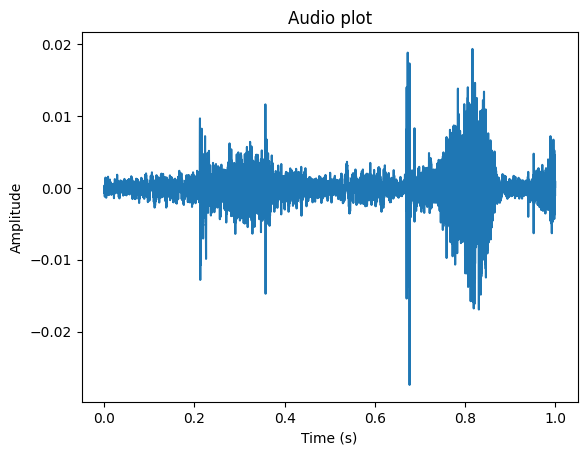

In [9]:
def load_normalized_audio(label: str, sample: str) -> tuple[int, np.ndarray]:
    ''' Takes in the class and the sample filename as arguments.
        Returns the sampling frequency and a normalized numpy array corresponding to the audio. '''
    fs, audio = wavfile.read(f'./dataset/{label}/{sample}')
    max_freq = np.iinfo(audio.dtype).max
    audio_norm = audio / max_freq
    return fs, audio_norm

fs, audio = load_normalized_audio('_silence_', sample_filenames['_silence_'][0])
audio, visualize(audio, fs)

### Ex. 2.4.

(array([-6.10370190e-05,  0.00000000e+00,  0.00000000e+00, ...,
        -1.12918485e-03,  9.76592303e-04,  1.22074038e-04]),
 array([0.00015798, 0.00015885, 0.00015945, ..., 0.00086001, 0.00085795,
        0.00085691]),
 None)

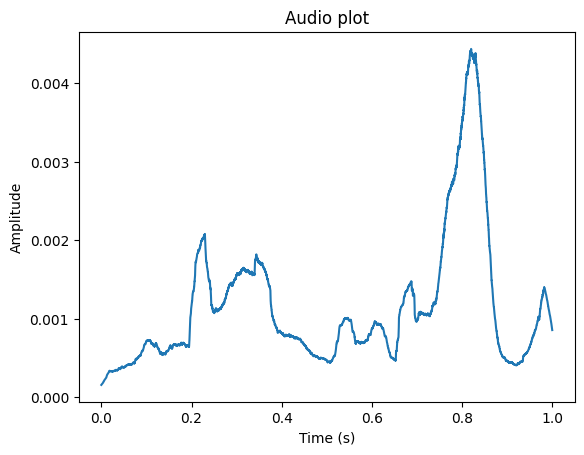

In [ ]:
def envelope(audio: np.ndarray, window: int) -> np.ndarray:
    ''' Takes in a normalized numpy array and a window. 
        Returns an audio envelope of the array, according to the provided window. '''
    res = []
    if window == 1:
        res = np.abs(np.array(audio))
        return res
    for i in range(len(audio)):
        # Get the audio the window covers (window > 0 and window < len(audio))
        truncated_list = audio[max(0, i-(window//2)):min(i+(window//2), len(audio)-1)]

        # Compute the absolute values and sum using numpy (to enhance speed)
        sum_res = np.sum(np.abs(np.array(truncated_list)))

        # Calculate the mean of the window
        res.append(sum_res/window)
    return np.array(res)

audio_envelope = envelope(audio, 561)
audio, audio_envelope, visualize(audio_envelope, fs)

### Ex. 2.5.

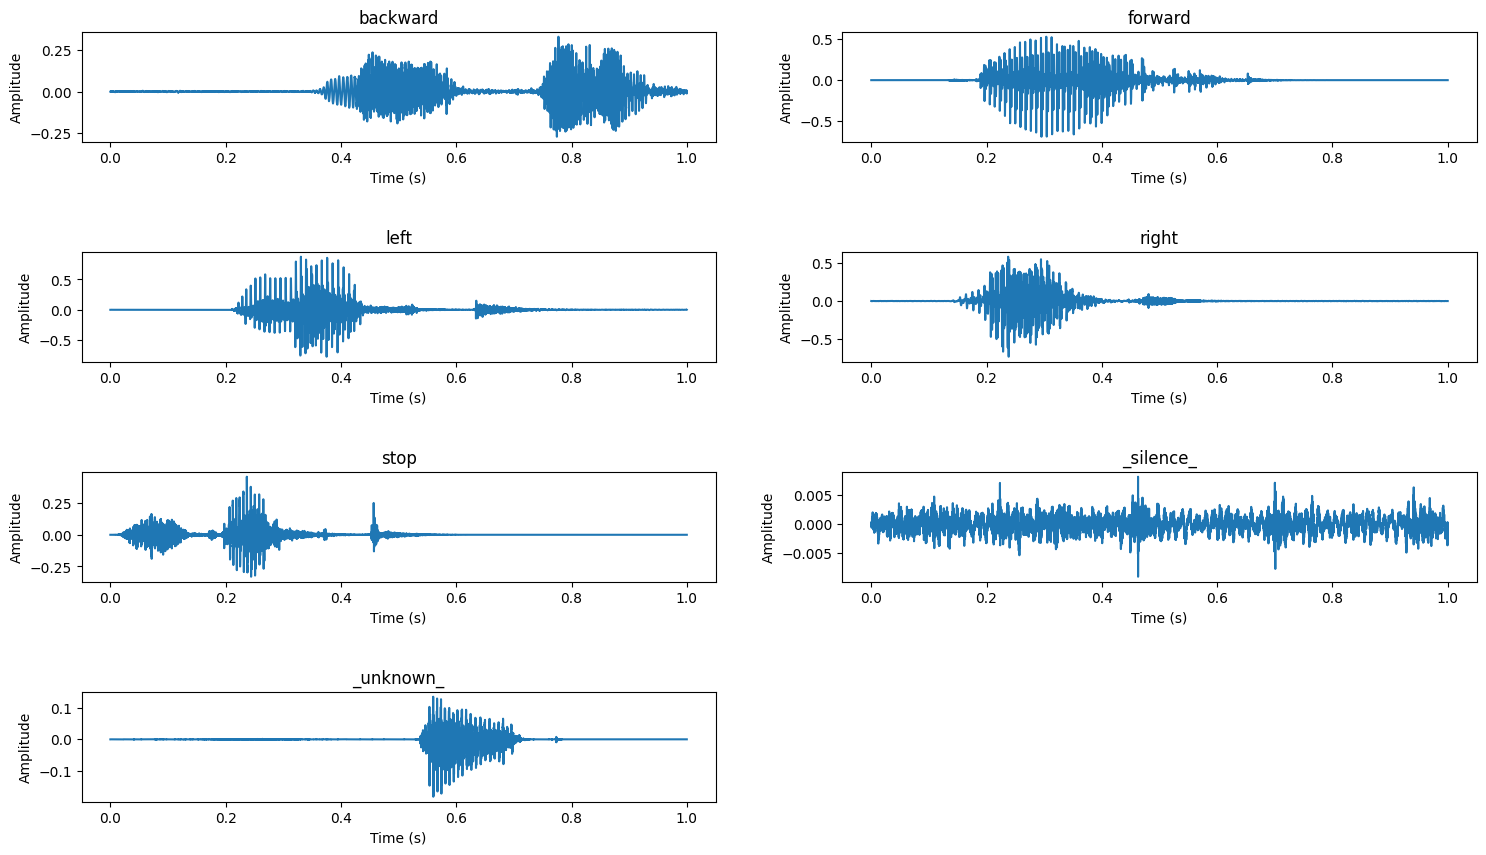

In [7]:
def plot_each_class(sample_filenames: dict) -> None:
    ''' Takes in a dictionary with audio filenames grouped by class.
        Plots a random sound from each class. '''
    files = np.random.randint(low=0, high=409, size=7)
    classes = list(iter(sample_filenames.keys()))  # List of classes from dictionary with sample filenames
    
    plt.figure(figsize=(18, 10))
    for i in range(len(files)):
        fs, audio = load_normalized_audio(classes[i], sample_filenames[classes[i]][files[i]])
        plot_data = []
        time = []

        # Time the audio
        for j in range(fs+1):
            time.append(j*(1/fs))  # Time depends on sampling frequency
            plot_data.append(0 if j >= len(audio) else audio[j])  # Append audio and zero padding after array
        plot_data = np.array(plot_data)

        plt.subplot(4, 2, i+1)
        plt.plot(time, plot_data)
        plt.xlabel("Time (s)")
        plt.ylabel("Amplitude")
        plt.title(classes[i])
        plt.subplots_adjust(wspace=0.2, hspace=1.0)

plot_each_class(sample_filenames)

## Ex. 3

### Ex. 3.1.

In [ ]:
def sound_durations(sample_filenames: dict, label: str) -> np.ndarray:
    ''' Takes in a dictionary with audio filenames grouped by class and a class.
        Returns an array of sound durations of the specified class. '''
    durations = []
    for filename in tqdm(sample_filenames[label]):
        fs, audio = load_normalized_audio(label, filename)
        durations.append(len(audio) / fs)
    durations_np = np.array(durations)
    return durations_np

# First 20 durations of the _unknown_ class
sound_durations(sample_filenames, "_silence_")

100%|██████████| 408/408 [00:03<00:00, 120.52it/s]


array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

### Ex. 3.2.

In [ ]:
def avg_env_amp(sample_filenames: dict, label: str, window: int) -> np.ndarray:
    ''' Takes in a dictionary with audio file names grouped by class, a class and envelope window size. 
        Returns an array with the average envelope amplitudes of each sound. '''
    amplitudes = []
    for filename in tqdm(sample_filenames[label]):
        _, audio = load_normalized_audio(label, filename)
        amp_mean = np.mean(envelope(audio, window))
        amplitudes.append(amp_mean)
    return np.array(amplitudes)

# Amplitude means of the stop class
avg_env_amp(sample_filenames, "stop", 1)

100%|██████████| 3872/3872 [00:30<00:00, 127.00it/s]


array([0.00676798, 0.01409336, 0.01183545, ..., 0.01169134, 0.0230213 ,
       0.01300074])

### Ex. 3.3.

In [ ]:
def outlier_detection(values: np.ndarray, method: str, k: int) -> tuple[int, np.ndarray]:
    ''' Takes in an array of values, an outlier detection method and a k-value.
        For reference: zscore -> k=3, iqr -> k=1.5.
        Returns the outlier density and the index array of outliers. '''
    mean = np.mean(values)
    stddev = np.std(values)
    outliers_index = []
    
    if (method == 'zscore'):
        for i in range(len(values)):
            zscore = (values[i] - mean) / stddev
            if (abs(zscore) > k):
                outliers_index.append(i)
    
    elif (method == 'iqr'):
        q1 = np.quantile(values, 0.25)
        q3 = np.quantile(values, 0.75)
        iqr = q3 - q1
        lower_bound = q1 - k*iqr
        upper_bound = q3 + k*iqr
        print(lower_bound, upper_bound)
        for i in range(len(values)):
            if not (lower_bound <= values[i] <= upper_bound):
                outliers_index.append(i)

    else:
        raise Exception("Invalid method")
    
    outlier_density = (len(outliers_index) / len(values))*100
    return outlier_density, outliers_index

### Ex. 3.4.

#### Ex. 3.4.1.

In [ ]:
def dur_amp_histogram(sample_filenames: dict, method: str, k=1) -> None:
    ''' Takes in a dictionary with audio filenames grouped by class and a data transformation function.
        Plots the histogram for the sound durations or mean amplitudes of each class. '''
    labels = list(iter(sample_filenames.keys()))
    plt.figure(figsize=(18, 10))

    for i in range(len(labels)):
        data = None
        if method == 'duration':
            data = sound_durations(sample_filenames, labels[i])
        elif method == 'mean_amp':
            data = avg_env_amp(sample_filenames, labels[i], k)
        else:
            raise Exception("Invalid method")

        plt.subplot(4, 2, i+1)
        plt.hist(data)
        plt.xlabel("Duration" if method == 'duration' else "Amplitude means")
        plt.ylabel("Frequency")
        plt.title(labels[i])
        plt.subplots_adjust(wspace=0.2, hspace=1.0)

100%|██████████| 635/635 [00:05<00:00, 118.00it/s]


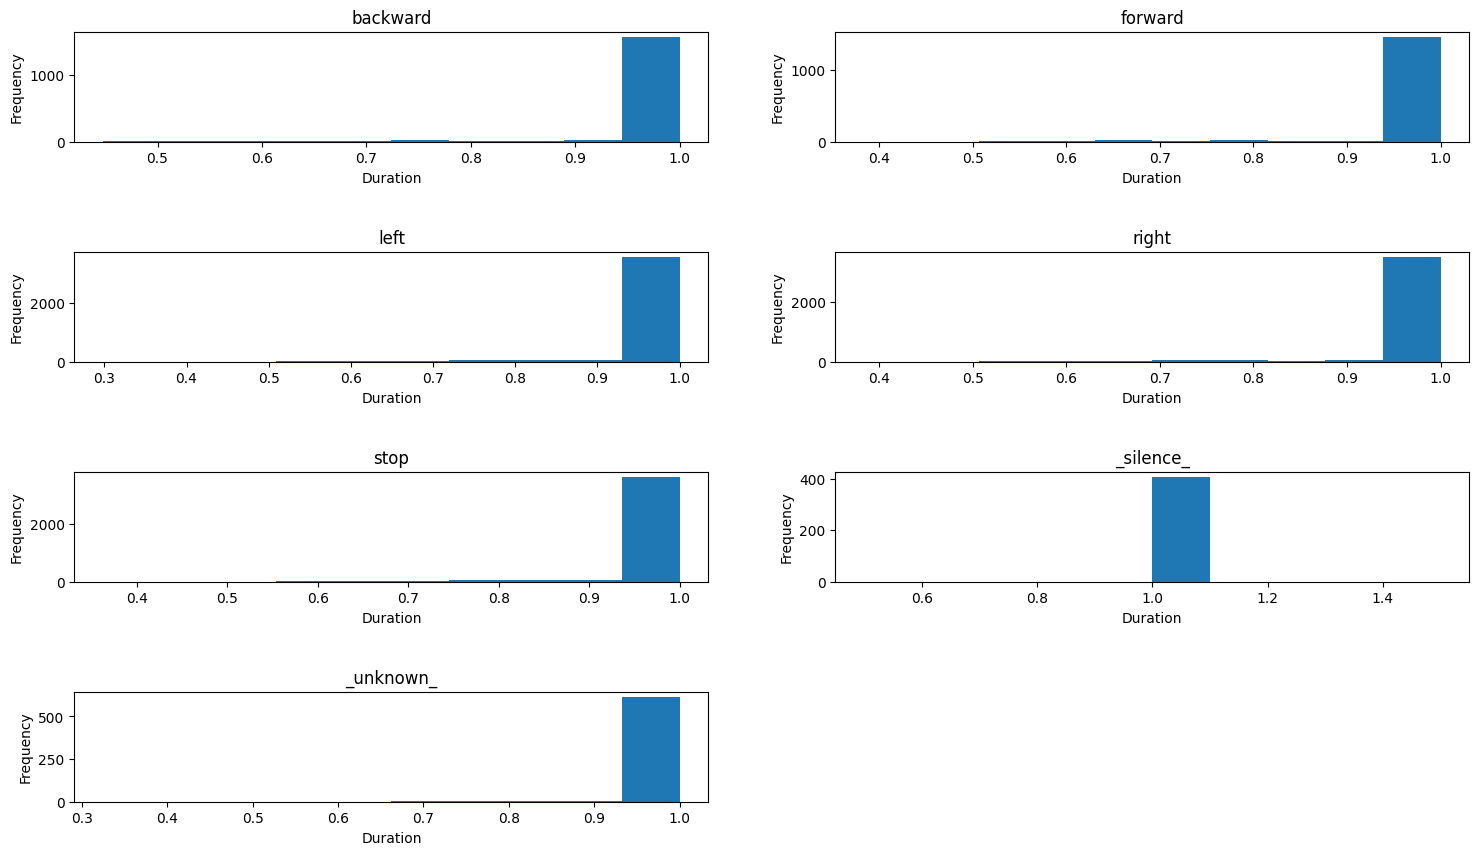

In [ ]:
# Durations histograms
dur_amp_histogram(sample_filenames, 'duration')

100%|██████████| 635/635 [00:00<00:00, 3469.74it/s]


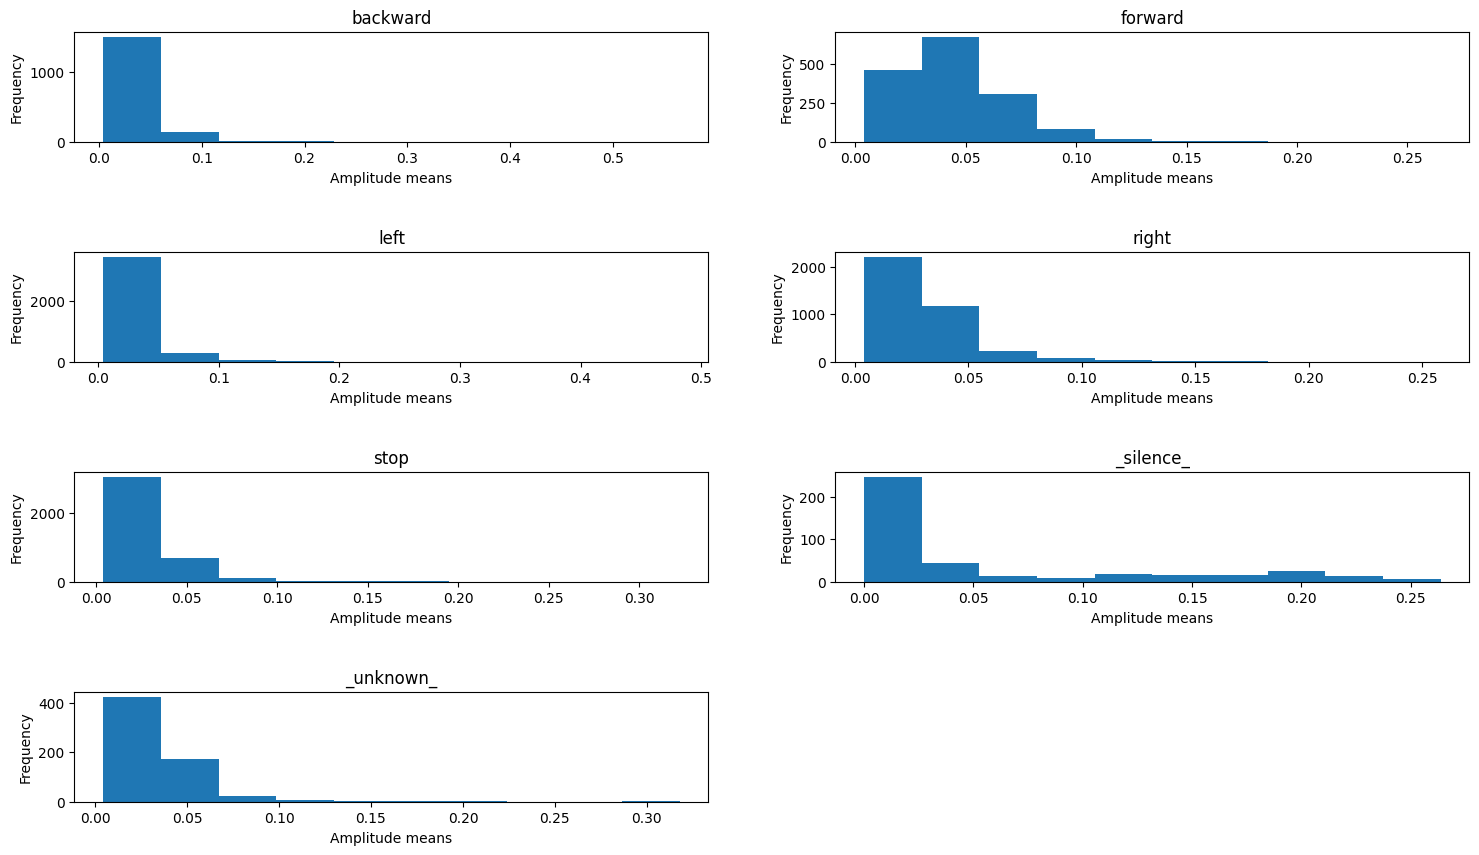

In [ ]:
# Mean amplitude histograms
dur_amp_histogram(sample_filenames, 'mean_amp', 1)

#### Ex. 3.4.2.

In [ ]:
def plot_outliers(sample_filenames: dict, processing_method: str, outlier_method: str, k1=1, k2=3) -> None:
    ''' Takes in a dictionary with audio filenames grouped by class and a data transformation function.
        k1 corresponds to the avg_env_amp k argument. 
        k2 corresponds to the outlier_detection k argument.
        Plots a scatter plot with for the sound durations of each class. '''
    labels = list(iter(sample_filenames.keys()))
    plt.figure()

    for i in range(len(labels)):
        data = None
        if processing_method == 'duration':
            data = sound_durations(sample_filenames, labels[i])
        elif processing_method == 'mean_amp':
            data = avg_env_amp(sample_filenames, labels[i], k1)
        else:
            raise Exception("Invalid processing method (use duration or mean_amp)")
    
        _, indexes = outlier_detection(data, outlier_method, k2)

        # Plot outliers for a label
        x = [labels[i]] * len(indexes)  # Array of size of outlier array
        plt.scatter(x, data[indexes], color='orange', label='outliers')

        # Plot rest for the same label
        y = np.delete(data, indexes)  # Data array without the outliers
        x = [labels[i]] * len(y)  # Array of size of non-outlier array
        plt.scatter(x, y, color='blue', label='all')
    
    plt.xlabel("Label")
    plt.ylabel("Durations" if processing_method == 'duration' else "Amplitude means")
    plt.title("Duration of samples" if processing_method == 'duration' else "Amplitude means of samples")

100%|██████████| 408/408 [00:00<00:00, 5615.12it/s]
C:\Users\ivosi\AppData\Local\Temp\ipykernel_15188\3636569417.py:11: RuntimeWarning: invalid value encountered in scalar divide
  zscore = (values[i] - mean) / stddev
100%|██████████| 635/635 [00:00<00:00, 5520.21it/s]


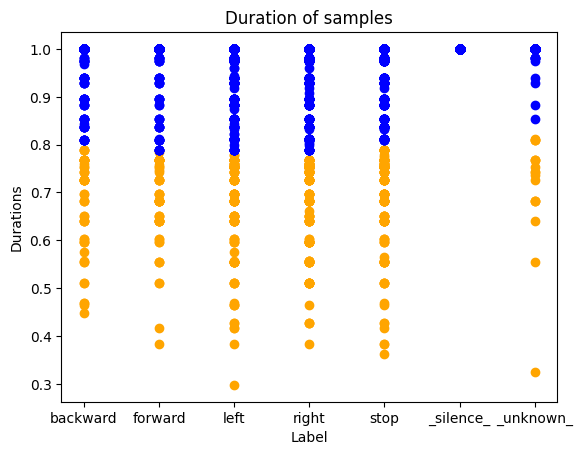

In [ ]:
# Plot duration outliers according to zscore using k=3
plot_outliers(sample_filenames, 'duration', 'zscore', k2=3)

#### Ex. 3.4.3.

In [ ]:
# Obtain the outlier densities for average amplitudes with k values 3, 3.5 and 4
k_values = [3, 3.5, 4]
labels = list(iter(sample_filenames.keys()))
zdensities = []
idensities = []
for k in k_values:
    k_zdensities = []
    k_idensities = []

    for label in labels:
        density1, _ = outlier_detection(avg_env_amp(sample_filenames, label, 1), 'zscore', k)
        density2, _ = outlier_detection(avg_env_amp(sample_filenames, label, 1), 'iqr', k)
        k_zdensities.append(density1)
        k_idensities.append(density2)

    zdensities.append(k_zdensities)
    idensities.append(k_idensities)

100%|██████████| 1664/1664 [00:00<00:00, 3612.55it/s]


-0.04857007955793939 0.11239814304406873


100%|██████████| 1557/1557 [00:00<00:00, 5038.47it/s]


-0.07068393314920499 0.15474388676107056


100%|██████████| 3801/3801 [00:01<00:00, 3293.09it/s]


-0.04910851046784877 0.09597160061952575


... (32 outputs left out)

100%|██████████| 408/408 [00:00<00:00, 3347.24it/s]


-0.3059499711027864 0.39138098448896763


100%|██████████| 635/635 [00:00<00:00, 4005.83it/s]

-0.0884148514511551 0.1425536019470809


In [ ]:
# Print the values
for k in range(len(k_values)):
    print(f"K = {k_values[k]}")
    for i in range(len(zdensities[k])):
        print(f"{labels[i]}: zscore = {zdensities[k][i]:.2f}% | iqr = {idensities[k][i]:.2f}%")
    print(f"Mean: zscore = {np.mean(zdensities[k]):.2f}% | iqr = {np.mean(idensities[k]):.2f}%\n")

print(f"Average z-score density difference: {np.mean(np.array(zdensities[-1]) - np.array(zdensities[0]))}")
print(f"Average iqr density difference: {np.mean(np.array(idensities[-1]) - np.array(idensities[0]))}")

K = 3
backward: zscore = 1.14% | iqr = 1.26%
forward: zscore = 1.22% | iqr = 0.64%
left: zscore = 1.82% | iqr = 2.21%
right: zscore = 1.88% | iqr = 1.67%
stop: zscore = 1.63% | iqr = 1.76%
_silence_: zscore = 0.00% | iqr = 0.00%
_unknown_: zscore = 1.42% | iqr = 1.10%
Mean: zscore = 1.30% | iqr = 1.23%

K = 3.5
backward: zscore = 0.84% | iqr = 1.02%
forward: zscore = 0.83% | iqr = 0.19%
left: zscore = 1.39% | iqr = 1.58%
right: zscore = 1.48% | iqr = 1.32%
stop: zscore = 1.29% | iqr = 1.37%
_silence_: zscore = 0.00% | iqr = 0.00%
_unknown_: zscore = 1.10% | iqr = 1.10%
Mean: zscore = 0.99% | iqr = 0.94%

K = 4
backward: zscore = 0.72% | iqr = 0.78%
forward: zscore = 0.64% | iqr = 0.19%
left: zscore = 1.03% | iqr = 1.16%
right: zscore = 1.16% | iqr = 1.01%
stop: zscore = 1.14% | iqr = 1.21%
_silence_: zscore = 0.00% | iqr = 0.00%
_unknown_: zscore = 0.94% | iqr = 0.94%
Mean: zscore = 0.81% | iqr = 0.76%

Average z-score density difference: -0.49511157273774536
Average iqr density differ

In the output of the above code cell, we can see the outlier density using z-score and iqr for 3 differente k values (3, 3.5 and 4), across all the classes.
From the results, we can observe that, given a certain k value, iqr has a lower tolerance than z-score to admit a value as an outlier, since it appears to be the metric that perceives a lower outlier density. However, if we compute the outlier density differences between k=3 and k=4, we'll find that z-score is the metric that, on average, had a higher decrease in outlier density. This sensitivity to the changes in k value for z-score is further corroborated when we compute the outlier densities for k values beyond 4, where we see that z-score becomes the metric that admits the lowest outlier density out of the 2.
In conclusion, although z-score is the most sensitive to parameter changes, both metrics seem to agree on an outlier density of around 0.8% to 1.3% when k varies between 3 and 4.

### Ex. 3.5.

In [ ]:
class Point:
    ''' Defines a 2D data point, where x is the duration and y is the mean amplitude'''
    def __init__(self, dur: int, amp: int):
        self.dur = dur
        self.amp = amp
    
    def __str__(self):
        return f"({self.dur}, {self.amp})"
    
    def to_tuple(self) -> tuple[int, int]:
        ''' Returns the Point in tuple form. '''
        return (self.dur, self.amp)
    
    def to_list(self) -> list[int, int]:
        ''' Returns the Point in list form. '''
        return [self.dur, self.amp]

def get_2D_data(sample_filenames: dict, label: str) -> list[Point]:
    ''' Takes in a dictionary with audio file names grouped by class and a class/label. 
        Returns a list with 2D data points containing the durations and mean amplitudes of the audio files from the specified class. '''
    points = []
    durations = sound_durations(sample_filenames, label)
    amplitudes = avg_env_amp(sample_filenames, label, 1)
    for i in range(len(durations)):
        points.append(Point(durations[i], amplitudes[i]))

    return points

In [ ]:
def distance_2(point1: Point, point2: tuple[int, int], method: str):
    ''' Takes in 2 points and a distance calculation method.
        Returns the computed distance, based on the calculation method provided. '''
    dist = None

    # Manhattan distance - Best for high-dimensional data and robust to outliers
    if method == 'L1':
        dur2, amp2 = point2
        dist = np.abs(point1.dur - dur2) + np.abs(point1.amp - amp2)

    # Euclidean distance - Best for low noise and to create spherical clusters
    elif method == 'L2':
        arr1 = np.array(point1.to_tuple())
        arr2 = np.array(point2)
        dist = np.linalg.norm(arr1 - arr2)

    else:
        raise Exception("Invalid distance calculation method (use L1 or L2)")
    
    return dist

def compute_centroid(cluster: list[Point]) -> tuple[int, int]:
    ''' Takes in a list (cluster) of Points.
        Returns the computed centroid (tuple) of the cluster of Points. '''
    durs = np.array([pt.dur for pt in cluster])
    amps = np.array([pt.amp for pt in cluster])
    return (np.mean(durs), np.mean(amps))   

In [ ]:
# Based on the pseudocode present in Wikipedia
def k_means_cluster(k: int, points: list[Point], method='L1') -> tuple[list[list[Point]], list[tuple[int, int]]]:
    ''' Takes in a k number of centroids, a list of points and a distance calculation method as arguments.
        Computes the K-Means cluster algorithm with the given arguments. 
        Returns a list with lists (clusters) of Points and the list of centroids (tuples).'''
    # The Forgy method of initialization
    np.random.shuffle(points)
    centroids = [pt.to_tuple() for pt in points[:k]]

    clusters = [[] for _ in range(k)]
    converged = False
    iteration = 1

    while not converged:
        # Reset clusters after each iteration
        clusters = [[] for _ in range(k)]

        for point in points:
            # Distance of the point to each centroid
            distances_to_centroids = np.array([distance_2(point, centroid, method) for centroid in centroids])

            # Get the closest centroid to the point
            cluster_assignment = np.argmin(distances_to_centroids)

            # Assign point to the cluster of the centroid above
            clusters[cluster_assignment].append(point)
            
        new_centroids = [compute_centroid(cluster) for cluster in clusters]
        converged = (new_centroids == centroids)
        centroids = new_centroids

        if converged:
            print(f"Total iterations: {iteration}")
            return clusters, centroids
        
        iteration += 1

### Ex. 3.6. and Ex. 3.7.

In [ ]:
def plot_clusters(clusters: list[list[Point]], centroids: list[tuple[int, int]]) -> None:
    ''' Takes in the list of clusters (lists of points) and centroids (tuples).
        Plots the clusters and corresponding centroids. '''
    plt.figure()
    
    for i in range(len(clusters)):
        x = [pt.dur for pt in clusters[i]]
        y = [pt.amp for pt in clusters[i]]
        plt.scatter(x, y, label=i)
    
    centroids_dur = [dur for (dur, _) in centroids]
    centroids_amp = [amp for (_, amp) in centroids]
    plt.scatter(centroids_dur, centroids_amp, s=80, color='k')
    plt.xlabel("Duration")
    plt.ylabel("Average amplitude")
    plt.legend()
    plt.show()

100%|██████████| 635/635 [00:00<00:00, 3620.00it/s]


Total iterations: 18


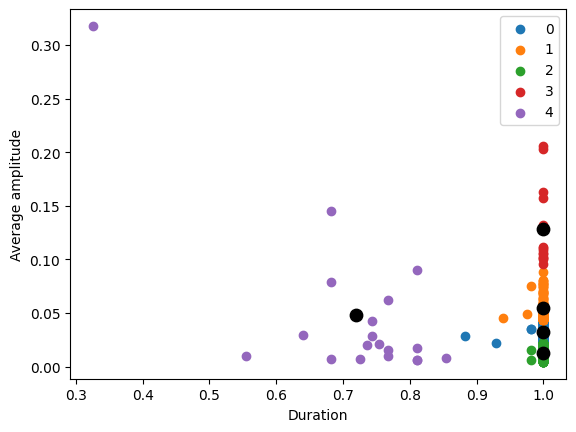

In [ ]:
# Clusters for the _unknown_ class with k=5 and euclidean distance
points = get_2D_data(sample_filenames, '_unknown_')
clusters, centroids = k_means_cluster(k=5, points=points, method='L2')
plot_clusters(clusters, centroids)

#### Example 1: _unknown_ class, k=5, euclidean distance

If we apply K-means to the _unknown_ class with the hyperparameters above, we seem to get 4 clusters that are closely aligned with each other and 1 "outlier" cluster. This "outlier" cluster seems to aggregate all the sounds with duration less or equal to around 0.85s. If we recall the plot produced in 3.4.2. to detect duration outlier using zscore with k=3, we can see that the results are very similar to those of this clustering instance, as both of them have sounds with around 0.8s or less in the outlier cluster.

100%|██████████| 1557/1557 [00:00<00:00, 3433.45it/s]


Total iterations: 12


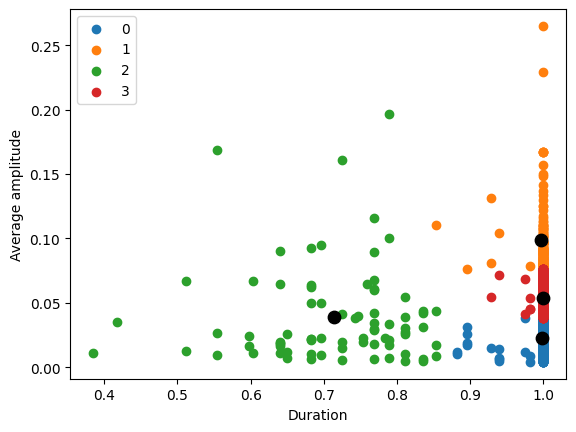

In [ ]:
# Clusters for the forward class with k=4 and euclidean distance
points = get_2D_data(sample_filenames, 'forward')
clusters, centroids = k_means_cluster(k=4, points=points, method='L2')
plot_clusters(clusters, centroids)

100%|██████████| 1557/1557 [00:00<00:00, 2756.87it/s]


Total iterations: 33


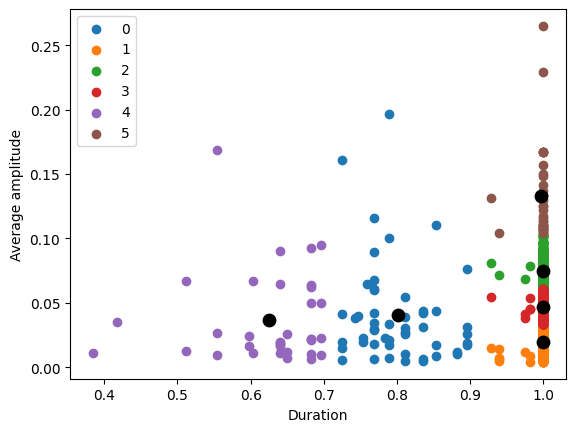

In [ ]:
# Clusters for the forward class with k=6 and euclidean distance
points = get_2D_data(sample_filenames, 'forward')
clusters, centroids = k_means_cluster(k=6, points=points, method='L2')
plot_clusters(clusters, centroids)

#### Example 2: forward class, k=4, euclidean class

As is the case with zscore and iqr, k-means also tends to create smaller "outlier" clusters with higher k-values. In the 2 plots above, we see that k-means, once again, considered the aggregated all sounds with duration with around 0.85s or less in the "outlier" cluster with k=4, while the rest of them seemed to align with each other. However, if we compute the algorithm for the same class with k=6, we see that the "outlier" cluster for duration has been reduced to sounds with 0.7s or less. This behaviour has also been observed with zscore and iqr and commented in 3.4.3 when comparing the two.

100%|██████████| 635/635 [00:00<00:00, 3881.49it/s]


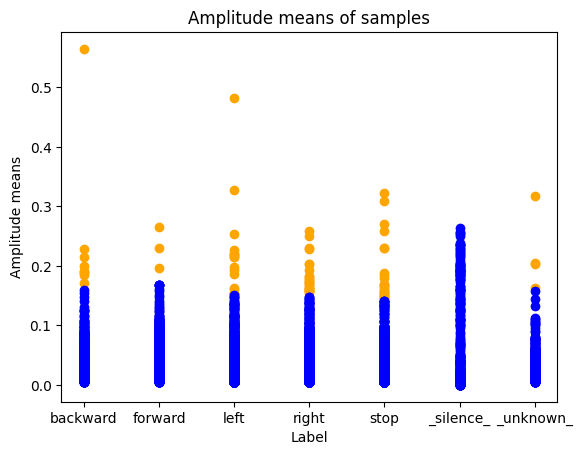

In [ ]:
# Plot duration outliers according to zscore using k=5
plot_outliers(sample_filenames, 'mean_amp', 'zscore', k2=5)

100%|██████████| 408/408 [00:00<00:00, 1866.48it/s]
C:\Users\ivosi\AppData\Local\Temp\ipykernel_7968\3636569417.py:11: RuntimeWarning: invalid value encountered in scalar divide
  zscore = (values[i] - mean) / stddev
100%|██████████| 635/635 [00:00<00:00, 1915.76it/s]


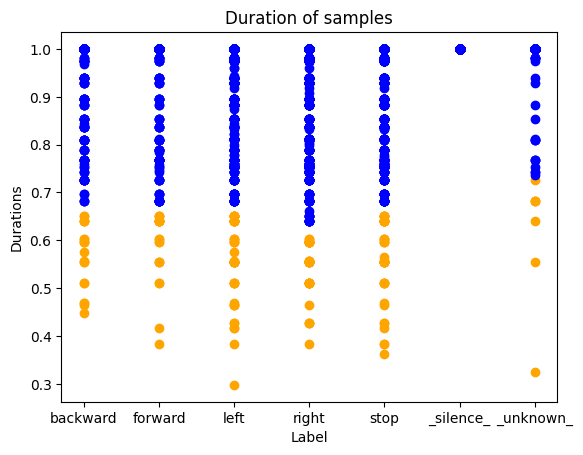

In [ ]:
# Plot duration outliers according to zscore using k=5
plot_outliers(sample_filenames, 'duration', 'zscore', k2=5)

100%|██████████| 3801/3801 [00:02<00:00, 1513.64it/s]


Total iterations: 49


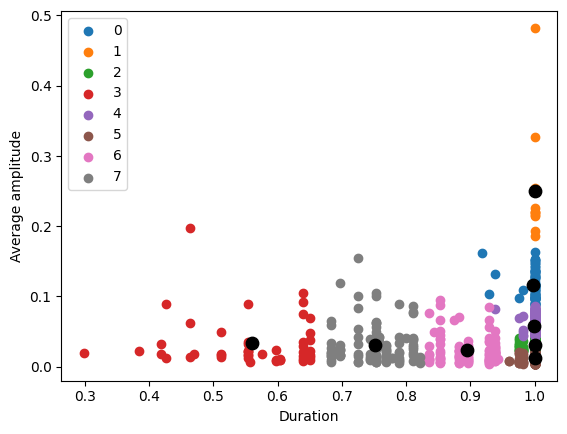

In [ ]:
# Clusters for the left class with k=8 and euclidean distance
points = get_2D_data(sample_filenames, 'left')
clusters, centroids = k_means_cluster(k=8, points=points, method='L2')
plot_clusters(clusters, centroids)

#### Example 3: left class, k=8, euclidean distance

Let's now compare the zscore outlier detection method for average amplitude and duration with k=5 and k-means clustering with k=8. If take a look at the average amplitude axis, we can see that both the "outlier" cluster and the zscore outlier classification are very similar to each other, with k-means having a slightly smaller number of samples in the aforementioned cluster. On the duration axis, k-means basically matched the zscore outlier classication, with both results also being very similar to each other. Also, notice that since we raised the k value on the zscore parameter, we also had to raise the value of the k hyperparameter on k-means to get a more closely matching cluster of outliers.
In conclusion, through k-means it is possible to compute the outliers for 2 different attributes with varying sensitivity according to the k hyperparameter (just like zscore and iqr).

#### Ex. 3.7.1.

In [ ]:
def plot_dbscan_clusters(model: DBSCAN, X: np.ndarray) -> None:
    ''' Takes in a DBSCAN model and a NumPy array of cluster data.
        Plots the clusters produced by the model (code from sklearn's documentation). '''
    labels = model.labels_
    unique_labels = set(labels)
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    core_samples_mask = np.zeros_like(labels, dtype=bool)
    core_samples_mask[model.core_sample_indices_] = True

    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    for k, col in zip(unique_labels, colors):
        if k == -1:
            # Black used for noise.
            col = [0, 0, 0, 1]

        class_member_mask = labels == k

        xy = X[class_member_mask & core_samples_mask]
        plt.plot(
            xy[:, 0],
            xy[:, 1],
            "o",
            markerfacecolor=tuple(col),
            markeredgecolor="k",
            markersize=14,
        )

        xy = X[class_member_mask & ~core_samples_mask]
        plt.plot(
            xy[:, 0],
            xy[:, 1],
            "o",
            markerfacecolor=tuple(col),
            markeredgecolor="k",
            markersize=6,
        )

    plt.xlabel('Duration')
    plt.ylabel('Amplitude')
    plt.title(f"Estimated number of clusters: {n_clusters_}")
    plt.show()

In [ ]:
# DBSCAN model for forward class with eps=0.6 and min_samples=10
dbscan_model = DBSCAN(eps=0.6, min_samples=10)

points = get_2D_data(sample_filenames, '_unknown_')
X = StandardScaler().fit_transform(np.array([pt.to_list() for pt in points]))
dbscan_model.fit(X)

# Number of clusters in labels, ignoring noise if present.
labels = dbscan_model.labels_
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

100%|██████████| 635/635 [00:00<00:00, 1617.22it/s]

Estimated number of clusters: 1
Estimated number of noise points: 27


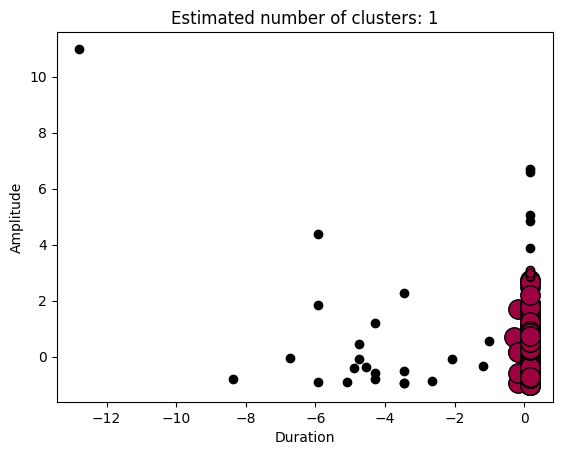

In [ ]:
plot_dbscan_clusters(dbscan_model, X)

##### Example 1: _unknown_ class, eps=0.6, min_samples=10, euclidean distance

In this first example, we can see that DBSCAN mostly agrees with the analysis done with the K-means algorithm. DBSCAN grouped most of the samples into a single cluster, with the remaining ones, i.e. those with duration less than 0.95s or mean amplitude over ~0.13 being classified as outliers. It should be noted that the sensitivity to outliers in DBSCAN can be tuned by changing hyperparameters such as eps, min_samples and distance measure, just like how zscore's k parameter and k-means k and distance measure hyperparameters.

In [ ]:
# DBSCAN model for forward class with eps=0.7 and min_samples=10
dbscan_model = DBSCAN(eps=0.7, min_samples=10)

points = get_2D_data(sample_filenames, 'forward')
X = StandardScaler().fit_transform(np.array([pt.to_list() for pt in points]))
dbscan_model.fit(X)

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

100%|██████████| 1557/1557 [00:00<00:00, 1575.79it/s]


Estimated number of clusters: 1
Estimated number of noise points: 27


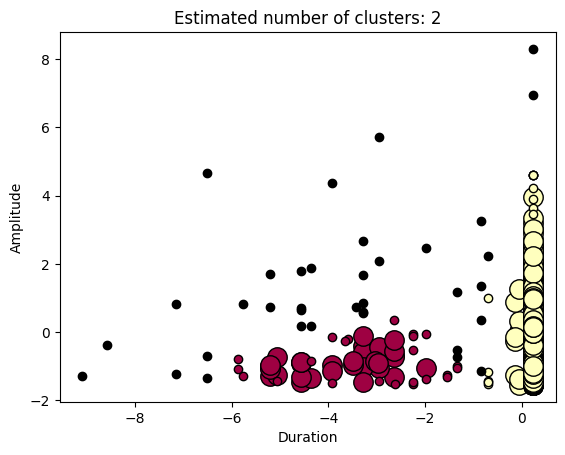

In [ ]:
plot_dbscan_clusters(dbscan_model, X)

##### Example 2: forward class, eps=0.7, min_samples=10, euclidean distance

Here, DBSCAN slightly contradicts our analysis. In this case, DBSCAN opted to create 2 clusters: one where most sample's duration and mean amplitude align (at duration=1s) and another at duration >0.6s and <0.9s and mean amplitude<0.05. Although both DBSCAN and the previous analysis agree than durations of 0.6s, it's interesting how it classified some samples in durations between 0.9s and 1s as outliers, as well as those with amplitudes over 0.05 and durations less than 0.9s. Despite this disagreement between methods, DBSCAN's results seem logical as all the points classified as outliers do seem more isolated than other grouped ones.

In [ ]:
# DBSCAN model for left class with eps=0.5 and min_samples=10
dbscan_model = DBSCAN(eps=0.5, min_samples=10)

points = get_2D_data(sample_filenames, 'left')
X = StandardScaler().fit_transform(np.array([pt.to_list() for pt in points]))
dbscan_model.fit(X)

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

100%|██████████| 3801/3801 [00:02<00:00, 1526.90it/s]


Estimated number of clusters: 1
Estimated number of noise points: 27


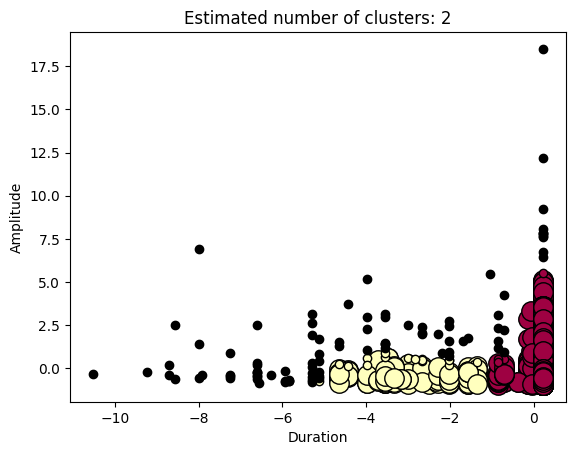

In [ ]:
plot_dbscan_clusters(dbscan_model, X)

##### Example 3: left class, eps=0.5, min_samples=10, euclidean distance

For this last example, a lower value of eps was used to increase DBSCAN's sensitivity to outliers. Once again, DBSCAN's results coincide with the analysis done in example 3 for k-means, since, in both examples, samples with duration of around 0.66s or less or mean amplitude of around 0.2 or more were classified as outliers. However, DBSCAN's results are more thorough than the one presented in K-means, as sounds with mean amplitude of around 0.6 or more and duration between 0.66s and 0.9s were also classified as outliers, contrary to the K-means analysis. In conclusion, although the outlier classification of both K-means and DBSCAN seem to coincide at some points, DBSCAN presents a more thorough and precise classification of outliers.

## Ex. 4

### Ex. 4.1.

In [ ]:
def noise_creation(sample_filenames: dict, label: str) -> np.ndarray:
    ''' Takes in a dictionary with audio file names grouped by class and a class/label.
        Gets the first 200 sounds of the specified class, downsamples with a factor of 100 and concatenates them.
        Returns the resulting concatenation of downsampled sounds. '''
    result = []
    for filename in sample_filenames[label][:200]:
        _, audio = load_normalized_audio(label, filename)
        audio_env = envelope(audio, 1)
        for i in range(0, len(audio_env), 100):  # Downsample by 100 - 1 out of every 100 data points
            result.append(audio_env[i])
    return np.array(result)

### Ex. 4.2.

In [ ]:
def noise_injection(audio: np.ndarray, noise_percentage: int) -> np.ndarray:
    ''' Takes in an audio array and a percentage of noise. 
        Returns the audio with the specified noise percentage inserted into it. '''
    assert 0 <= noise_percentage <= 100, "Noise percentage should be between 0 and 100"
    result = np.copy(audio)
    random_idx = np.random.randint(0, high=len(audio), size=round(len(audio) * noise_percentage/100))
    result[random_idx] = 1.5
    return result

#### Ex. 4.2.1.

In [ ]:
# Load audio samples from every class with 3% noise 
labels = list(iter(sample_filenames.keys()))
data = []
for label in labels:
    rand_idx = np.random.randint(0, len(sample_filenames[label]))
    fs, audio = load_normalized_audio(label, sample_filenames[label][rand_idx])
    audio = envelope(audio, 1)
    audio_noise = noise_injection(audio, 3)  # Audio with 3% of noise
    data.append(audio_noise)

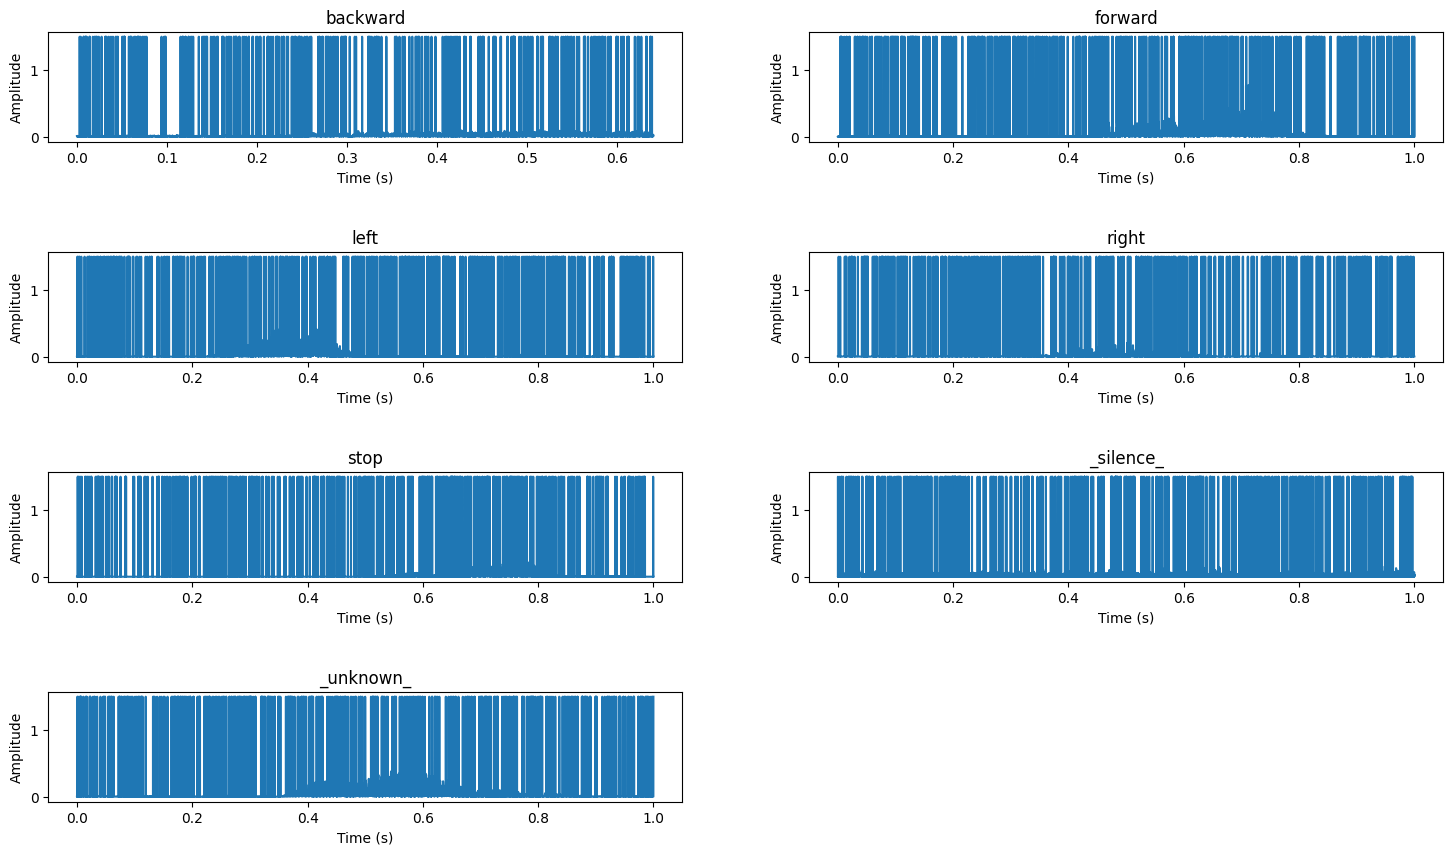

In [ ]:
# Audio plots for every class after the application of 3% of outliers
plt.figure(figsize=(18, 10))

for i in range(len(labels)):
    plt.subplot(4, 2, i+1)

    samples = data[i].shape[0]  # Number of samples
    time = [i*(1/fs) for i in range(0, samples)]  # Instants in seconds

    plt.plot(time, data[i])
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title(labels[i])
    plt.subplots_adjust(wspace=0.2, hspace=1.0)

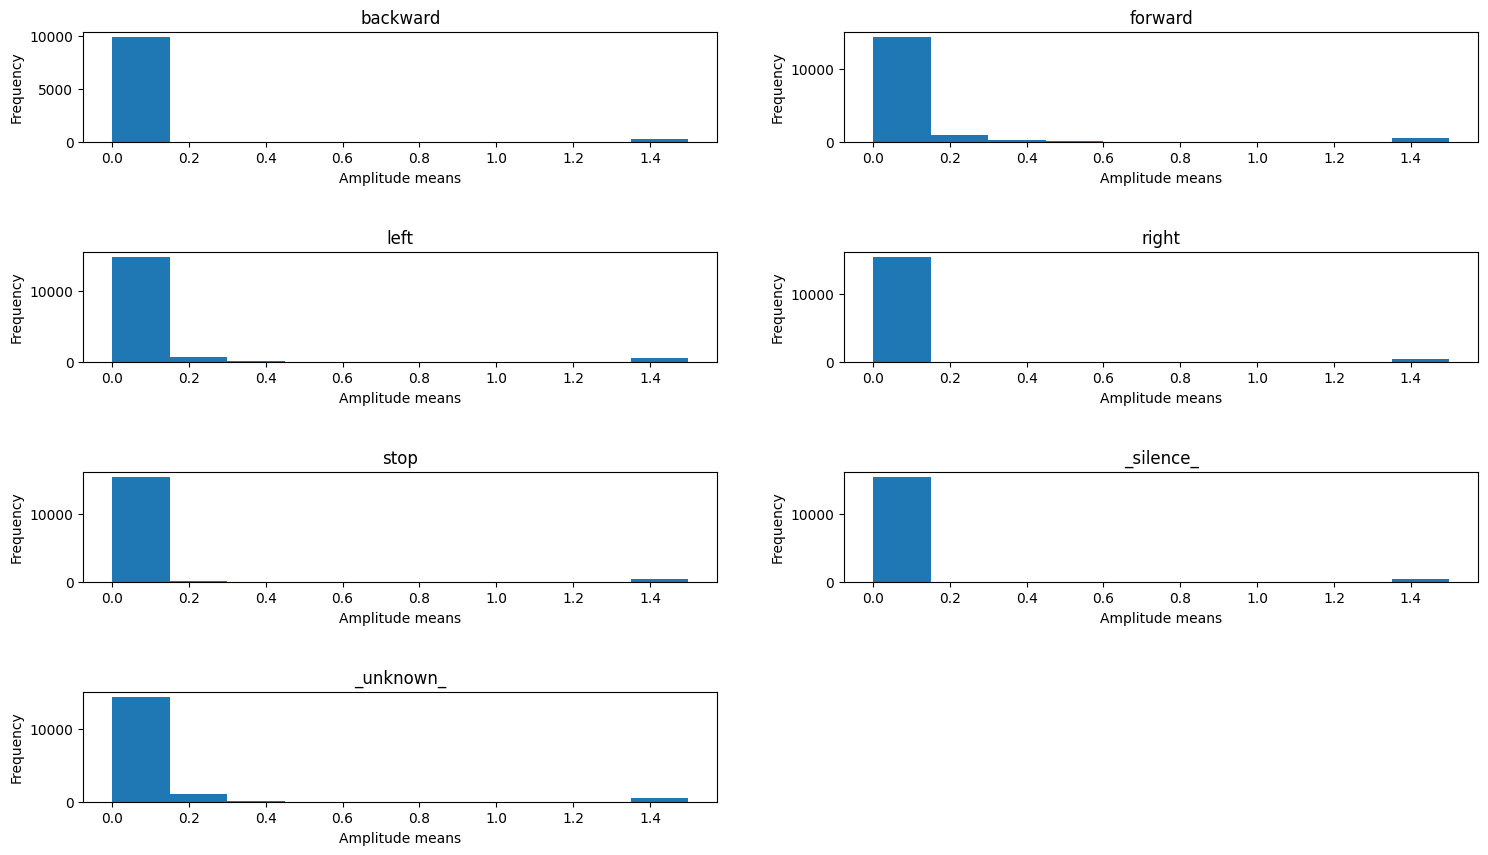

In [ ]:
# Histograms of the enveloped audio's amplitudes
plt.figure(figsize=(18, 10))
for i in range(len(labels)):
    audio = envelope(data[i], 1)

    plt.subplot(4, 2, i+1)
    plt.hist(audio)
    plt.xlabel("Amplitude means")
    plt.ylabel("Frequency")
    plt.title(labels[i])
    plt.subplots_adjust(wspace=0.2, hspace=1.0)

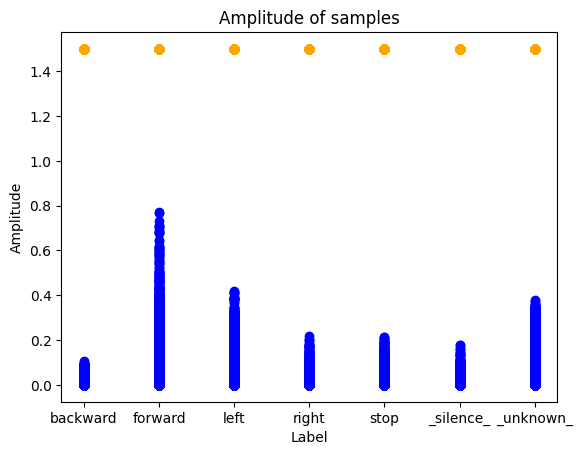

In [ ]:
# Outlier detection using the zscore method on frequencies of sounds
plt.figure()
for i in range(len(labels)):
    _, indexes = outlier_detection(data[i], 'zscore', k=3)

    # Plot outliers for a label
    x = [labels[i]] * len(indexes)  # Array of size of outlier array
    plt.scatter(x, data[i][indexes], color='orange', label='outliers')

    # Plot rest for the same label
    y = np.delete(data[i], indexes)  # Data array without the outliers
    x = [labels[i]] * len(y)  # Array of size of non-outlier array
    plt.scatter(x, y, color='blue', label='all')
    
    plt.xlabel("Label")
    plt.ylabel("Amplitude")
    plt.title("Amplitude of samples")

### Ex. 4.3.

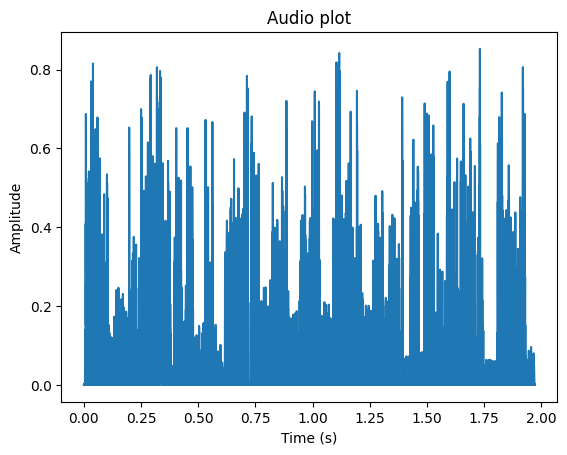

In [ ]:
noise = noise_creation(sample_filenames, 'forward')
time = [i/fs for i in range(len(noise))]
noise, time[-1]
visualize(noise, fs)

In [ ]:
def lin_reg(audio: np.ndarray, p: int) -> np.ndarray:
    ''' Takes in an audio array and a window p.
        Computes the beta values for linear regression. 
        Returns a NumPy array containing the beta values. '''
    X = np.array([audio[i-p:i] for i in range(p, len(audio))])
    X = np.insert(X, 0, 1, axis=1)
    y = np.array(audio[p:])
    betas = np.matmul(np.linalg.pinv(X), y)
    return betas

betas = lin_reg(noise, 10)
betas

array([ 0.00557222, -0.0221091 ,  0.02031458,  0.04005021,  0.06079943,
        0.05577267,  0.06547322,  0.11349761,  0.21714168,  0.1527204 ,
        0.16160078])

### Ex. 4.4.

In [ ]:
def restore_noisy_audio(sample_filenames: dict, label: str, noise_per: int, p: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    ''' Takes in a dictionary with audio file names grouped by class, a class/labeland, a percentage of noise and a window p (for linear regression).
        Returns a normal audio from the class, a noisy version of the audio and the restored version, according to linear regression. '''
    noise = noise_creation(sample_filenames, label)
    _, audio = load_normalized_audio(label, sample_filenames[label][3])
    audio = envelope(audio, 1)
    audio_noisy = noise_injection(audio, noise_per)
    lin_model = lin_reg(noise, p)

    audio_clean = np.copy(audio_noisy)
    for i in range(len(audio_clean)):
        if audio_clean[i] == 1.5:
            # If i<p, x and b only range to i
            x = audio_clean[max(0, i-p):i]  # x1, x2, ..., xp
            b = lin_model[1:min(len(lin_model), i+1)]  # b0, b1, ..., bp
            audio_clean[i] = lin_model[0] + np.sum(x * b)  # yi = b0 + x1*b1 + ... + xp*bp
    
    return audio, audio_noisy, audio_clean

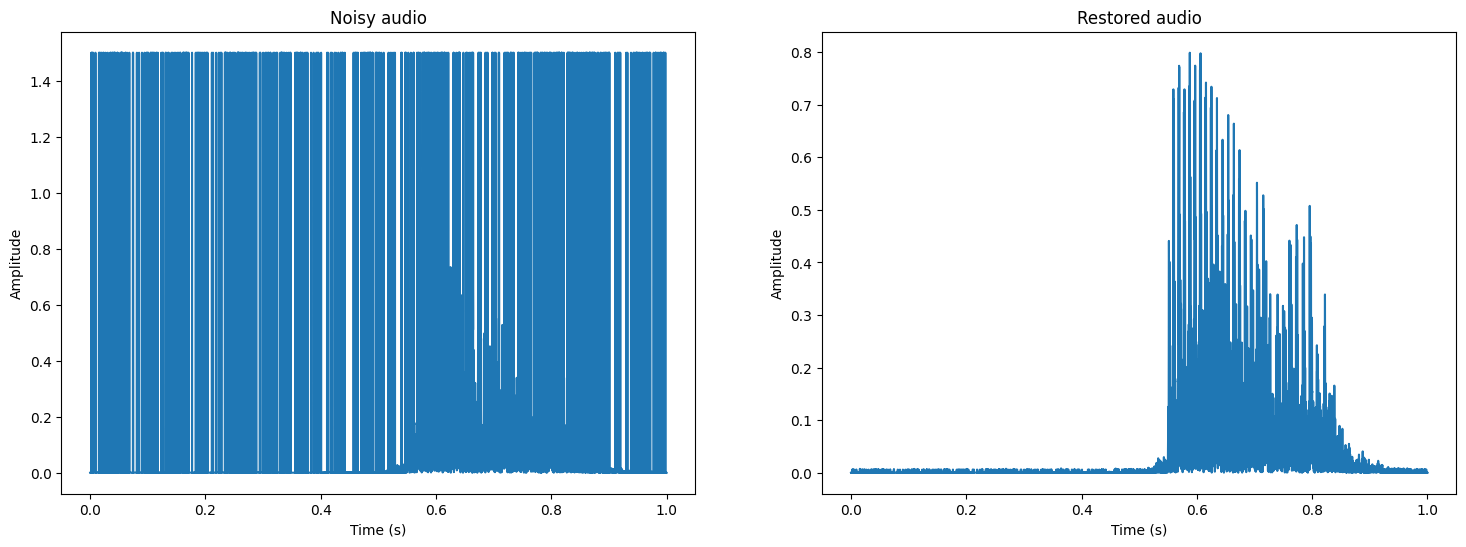

In [ ]:
# Introducing noise to a forward class audio and denoising it with linear regression
audio, audio_noisy, audio_clean = restore_noisy_audio(sample_filenames, 'forward', 3, 16)
time = [i/fs for i in range(len(audio_noisy))]

plt.figure(figsize=(18, 6))

plt.subplot(1, 2, 1)
plt.plot(time, audio_noisy)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Noisy audio")

plt.subplot(1, 2, 2)
plt.plot(time, audio_clean)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Restored audio")

plt.subplots_adjust(wspace=0.2, hspace=1.0)

In [ ]:
# Comparing RMSE between classes/labels (distorted vs restored audio)
scores = []
for label in labels:
    audio, audio_noisy, audio_clean = restore_noisy_audio(sample_filenames, label, 3, 16)
    noisy_score = np.sqrt(np.mean((audio - audio_noisy)**2))  # RMSE = sqrt((1/n)*(sum((y-y_pred)**2))
    clean_score = np.sqrt(np.mean((audio - audio_clean)**2))
    scores.append((noisy_score, clean_score))
    print(f"{label}: Noise score = {noisy_score} | Clean score = {clean_score}")

avg_red = np.mean([clean-noise for noise, clean in scores])
print(f"Average RMSE reduction = {avg_red}")

backward: Noise score = 0.25230781764374716 | Clean score = 0.008763271356350905
forward: Noise score = 0.2514724172234302 | Clean score = 0.008156793276393215
left: Noise score = 0.2507670285902986 | Clean score = 0.010680223295098941
right: Noise score = 0.25737775125160556 | Clean score = 0.0014031018356458918
stop: Noise score = 0.2533208587680988 | Clean score = 0.004306872204460403
_silence_: Noise score = 0.25797038991519977 | Clean score = 0.0007646894864701313
_unknown_: Noise score = 0.2564938586679786 | Clean score = 0.001157136065538669
Average RMSE reduction = -0.24921114779148576


#### Values for p

Values ranging from 1 to 100 were tested for p by comparing the RMSE (Root Mean Squared Error) average across all classes. Results showed that there wasn't significant difference for any value of p>3. Thus, a value of p=16 was chosen for being small and displaying consistently good results during testing. Below is the function used for testing values of p.

In [ ]:
def test_p_values(sample_filenames: dict, noise_per: int, limit: int) -> tuple[int, np.ndarray]:
    ''' Takes in a dictionary with audio file names grouped by class, a percentage of noise and window p limit to test.
        Computes the RMSEs for each class/label for each value of p.
        Returns the value of p for which the average RMSE was the lowest and the mean RMSEs for the classes. '''
    p_scores = []
    for p in tqdm(range(1, limit)):
        label_scores = []
        for label in labels:
            audio, _, audio_clean = restore_noisy_audio(sample_filenames, label, noise_per, p)
            label_scores.append(np.sqrt(np.mean((audio - audio_clean)**2)))
        p_scores.append(np.array(label_scores))
    p_scores = np.array(p_scores)
    p_scores_avg = np.array([np.mean(scores) for scores in p_scores])
    return np.argmin(p_scores_avg), p_scores_avg

### Ex. 4.5.

In [ ]:
def lin_reg_v2(audio: np.ndarray, p: int) -> np.ndarray:
    ''' Takes in an audio array and a window p.
        Computes the beta values for linear regression. 
        This second version takes the window centered on the point to be predicted instead of the points immediately before.
        Returns a NumPy array containing the beta values. '''
    # Note: p now denotes the amount of elements considered before and after the i-th element
    # Example: for p=2, y = x[i] and x = [x[i-2], x[i-1], x[i+1], x[i+2]]
    X = np.array([np.concat((audio[i-p:i], audio[i+1:i+p+1])) for i in range(p, len(audio)-p)])
    X = np.insert(X, 0, 1, axis=1)
    y = np.array(audio[p:len(audio)-p])
    betas = np.matmul(np.linalg.pinv(X), y)
    return betas

In [ ]:
def restore_noisy_audio_v2(sample_filenames: dict, label: str, noise_per: int, p: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    ''' Takes in a dictionary with audio file names grouped by class, a class/labeland, a percentage of noise and a window p (for linear regression).
        This second version takes the window centered on the point to be predicted instead of the points immediatly before.
        Returns a normal audio from the class, a noisy version of the audio and the restored version, according to linear regression. '''
    noise = noise_creation(sample_filenames, label)
    _, audio = load_normalized_audio(label, sample_filenames[label][3])
    audio = envelope(audio, 1)
    audio_noisy = noise_injection(audio, noise_per)
    lin_model = lin_reg_v2(noise, p)

    audio_clean = np.copy(audio_noisy)
    for i in range(len(audio_clean)):
        if audio_clean[i] == 1.5:
            # If i<p, x and b only range to i
            x = np.concat((audio_clean[max(0, i-p):i],  # xi-1, xi-2, ..., xi-p/2
                           audio_clean[i+1:min(len(audio_clean), i+p+1)]))  # xi+1, xi+2, ..., xi+p/2
            b = lin_model[max(1, p-i+1):min(len(lin_model), p+len(audio_clean)-i)]   # b0, b1, ..., bp
            audio_clean[i] = lin_model[0] + np.sum(x * b)   # yi = b0 + x1*b1 + ... + xp*bp

    return audio, audio_noisy, audio_clean

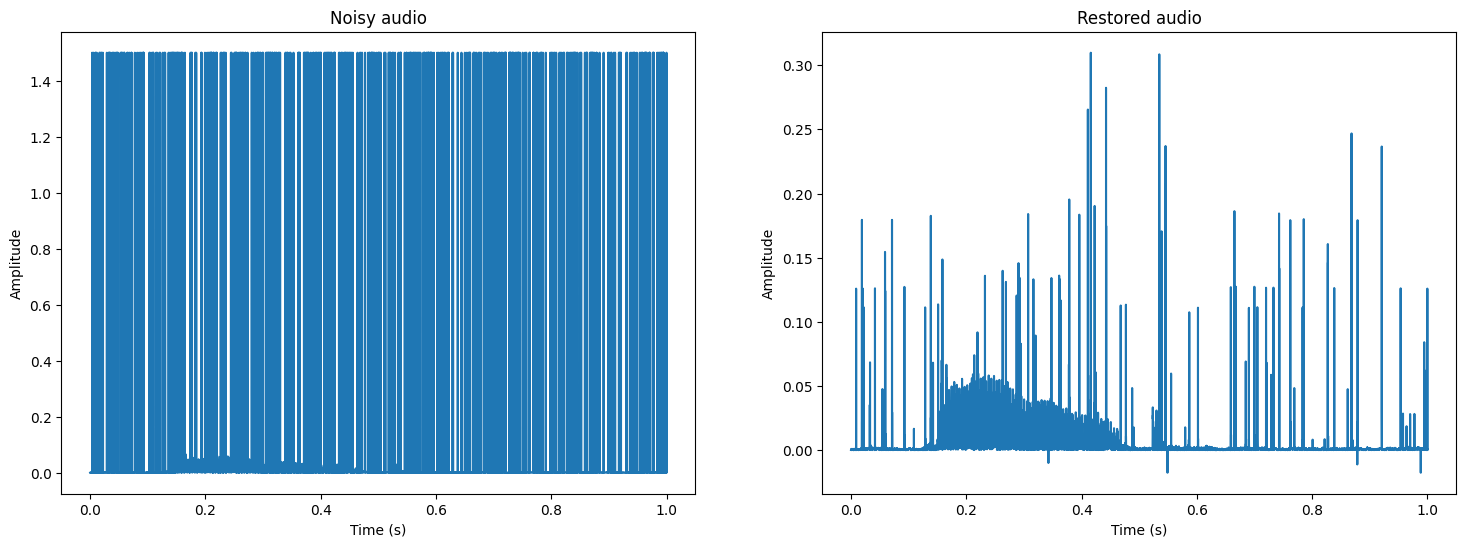

In [ ]:
# Introducing noise to a forward class audio and denoising it with linear regression
audio, audio_noisy, audio_clean = restore_noisy_audio_v2(sample_filenames, '_unknown_', 3, 11)
time = [i/fs for i in range(len(audio_noisy))]

plt.figure(figsize=(18, 6))

plt.subplot(1, 2, 1)
plt.plot(time, audio_noisy)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Noisy audio")

plt.subplot(1, 2, 2)
plt.plot(time, audio_clean)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Restored audio")

plt.subplots_adjust(wspace=0.2, hspace=1.0)

In [ ]:
def test_p_values_v2(sample_filenames: dict, noise_per: int, limit: int) -> tuple[int, np.ndarray]:
    ''' Takes in a dictionary with audio file names grouped by class, a percentage of noise and window p limit to test.
        Computes the RMSEs for each class/label for each value of p.
        This second version considers the restore_noisy_audio_v2 function
        Returns the value of p for which the average RMSE was the lowest and the mean RMSEs for the classes. '''
    p_scores = []
    for p in tqdm(range(1, limit)):
        label_scores = []
        for label in labels:
            audio, _, audio_clean = restore_noisy_audio_v2(sample_filenames, label, noise_per, p)
            label_scores.append(np.sqrt(np.mean((audio - audio_clean)**2)))
        p_scores.append(np.array(label_scores))
    p_scores = np.array(p_scores)
    p_scores_avg = np.array([np.mean(scores) for scores in p_scores])
    return np.argmin(p_scores_avg), p_scores_avg

In [ ]:
test_p_values_v2(sample_filenames, 3, 20)

100%|██████████| 19/19 [01:00<00:00,  3.16s/it]


(np.int64(17),
 array([0.01753621, 0.01473161, 0.0134343 , 0.01167078, 0.01176146,
        0.01090723, 0.01153897, 0.01056591, 0.01105182, 0.01107499,
        0.01118251, 0.01090584, 0.01062852, 0.010972  , 0.01067574,
        0.0106247 , 0.01088905, 0.01048957, 0.01094213]))

In [ ]:
test_p_values(sample_filenames, 3, 20)

100%|██████████| 19/19 [00:31<00:00,  1.65s/it]


(np.int64(8),
 array([0.00540868, 0.00459889, 0.00503072, 0.00504651, 0.00480972,
        0.0048941 , 0.00497423, 0.004725  , 0.00455473, 0.00479346,
        0.00501796, 0.00464986, 0.00520736, 0.00495911, 0.00497654,
        0.00473766, 0.00504932, 0.00543129, 0.00516896]))

#### Result analysis

Both the visual and statistical results prove that the method used in 4.4. to denoise the audio was more effective than the one in 4.5. According to the plots, the method used in 4.5. stil produced some slight spikes in frequency on the sound envelope, while the method in 4.4. seemed to mitigate all spikes successfully. This is also verified by the RMSE values, as the ones from 4.5. are twice as high as the ones on 4.4., which shows that the audios produced by the former display a higher deviation from the original than the latter. However, both methods seem to achieve their best results when the value of p is low (around 8-20), with this last method showing an amount of frequency spikes (due to noise) directly proportional to the value of p.

## Ex. 5

### Ex. 5.1. Feature extraction methods

#### MFCC (Mel-Frequency Cepstral Coefficients)

MFCCs are one of the best choices due to being quite popular among speech recognition tasks, somewhat simple and quite effective and robust. In speech recognition, MFCCs are used to extract human ear information, thus allowing to capture vocal tract features, which are essential in shaping speech sounds. There has already been some research about the feature extraction process using MFCCs and their usage in the audio classification of words:

[Mel Frequency Cepstral Coefficient and Its Applications: A Review](https://ieeexplore.ieee.org/stamp/stamp.jsp?tp=&arnumber=9955539)

[An Approach to Extract Feature using MFCC](https://iosrjen.org/Papers/vol4_issue8%20(part-1)/D04812125.pdf)

[Article on speech recognition and MFCC](https://jonathan-hui.medium.com/speech-recognition-feature-extraction-mfcc-plp-5455f5a69dd9)

There are also some variations of MFCC that try to improve on some aspects of this method that might be worth considering: Weighted MFCC, Wavelet-MFCC, Frequency Based Energy (FBE)-MFCC, MFCC with Vocal-Tract Length Normalization (VTLN).

#### Delta and Delta-Delta MFCC

Although MFCC are widely used and recognized as powerful features, speech signals are time-variant and are in a constant flux, which can be detrimental when computing only the instantaneous spectral envelope shape of the signal (MFCC). To capture those time relations of the speech, we can compute the delta (differential) and delta-delta (acceleration) of the sound. Although these aggravate noise presence in the data, the computation simplicity and the benefits over instantaneous features makes it a worthy trade-off:

[Deltas and Delta-deltas](https://speechprocessingbook.aalto.fi/Representations/Deltas_and_Delta-deltas.html)

[A novel approach for MFCC feature extraction](https://ieeexplore.ieee.org/document/5709752)

[A note on MFCC and delta features](https://desh2608.github.io/2019-07-26-delta-feats/)

#### Zero-Crossing Rate

Zero-Crossing Rate is a simple feature extraction method that computes the rate at which the signal alternates between positive and negative (given a certain threshold epsilon). This can be useful in cases where there's presence of noise and there exists a need to identify the presence of speech, since environmental noise has different statistics relative to speech in the signal's dominant frequency domain. There's plenty of articles/papers which have already discussed the usefulness of this method in audio classification tasks:

[Zero crossing rate](https://www.sciencedirect.com/topics/engineering/zero-crossing-rate)

#### PLP (Perceptual Linear Prediction)

PLP is also a great method for speech recognition due to its robustness against noise and variations in loudness. PLP captures the spectral envelope of a sound by capturing the vocal tract features as an all-pole filter and reflects human auditory senstivity (loudness) by warping the frequency axis to the Bark scale. Although they use different methodology, MFCC and PLP are similar when it comes to feature extraction, since both aim to extract vocal tract features and are robust to noise. Below is some research that delves deeper into this topic:

[Revising Perceptual Linear Prediction (PLP)](https://www5.informatik.uni-erlangen.de/Forschung/Publikationen/2005/Hoenig05-RPL.pdf)

[Perceptual linear predictive (PLP) analysis of speech](https://www.semanticscholar.org/paper/Perceptual-linear-predictive-(PLP)-analysis-of-Hermansky/b578f4faeb00b808e8786d897447f2493b12b4e9)

#### GFCC (Gammatone Filterbank Cepstral Coefficients)

GFCCs are a variation of MFCCs that are worth considering for speech recognition tasks when more noise robustness is required. Instead of using Mel coefficients, this feature extraction method uses gammatone filters to focus on human auditory processing of sounds by simultating the frequency tuning of the human ear, providing more feature robustness in noisy environments, Some studies were already conducted on this method, even comparing it to MFCC:

[Gammatone Filterbank Analyses and Comparisons between GFCC and MFCC](http://vaplab.ee.ncu.edu.tw/english/pcchang/pdf/c156.pdf)

From the above, MFCC and PLP are choices that should be considered for the task at hand, due to being very popular and well researched methods, with good robustness with respect to noise, along with Delta and Delta-deltas, to capture time-variant changes in signal, and Zero-crossing rate, also due to the robustness to noise, its simplicity and usefulness.

**Note**: PLP couldn't be implemented due to library incompatibility with the current environment. Delta and delta-delta coefficients of the MFCC will be used instead.

### Ex. 5.2.

In [ ]:
N_MFCC = 16
N_FFT = 1024
TARGET_SR = 16000

def get_mfcc_features(sample_filenames: dict, label: str, n_mfcc: int = 16, n_fft: int = 1024, target_sr: int = 16000, 
                      aggregation: bool = True) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    ''' Takes in a dictionary with audio file names grouped by class, a class/label, the number of MFCC and FFT (Fast Fourier Transforms), 
        a target sample rate and a value aggregation flag.
        The MFCC number will determine the number of features, FFT specifies the number of transformations of segments into the frequency spectrum, 
        target sample rate specifies the resample target rate to ensure all audios follow the same sample rate (the default in the dataset is 16000), aggregation specifies
        if each MFCC array will be aggregated (each MFCC is an array, not a value, thus we might need to process the array to reduce dimensionality).
        Returns 3 NumPy arrays corresponding to the MFCC, delta MFCC and delta-delta MFCC features the given class/label. '''
    mfcc_features = []
    dmfcc_features = []
    ddmfcc_features = []
    for filename in tqdm(sample_filenames[label]):
        sr, X = load_normalized_audio(label, filename)

        # Ensure all audios follow same sample rate (16000 in this case)
        X_res = librosa.resample(X, orig_sr=sr, target_sr=target_sr)

        # Zero padding for audios shorter than 1 second (less than 16000 samples)
        if len(X_res) < 16000:
            X_res = np.concatenate((X_res, np.zeros(16000-len(X_res))), axis=0)
        
        # MFCC feature extraction 
        X_mfcc = librosa.feature.mfcc(y=X_res, sr=target_sr, n_mfcc=n_mfcc, n_fft=n_fft)
        X_dmfcc = librosa.feature.delta(data=X_mfcc)
        X_ddmfcc = librosa.feature.delta(data=X_mfcc, order=2)

        # Standardize the MFCCs
        scaler = StandardScaler()
        X_mfcc_scaled = scaler.fit_transform(X_mfcc)
        scaler = StandardScaler()
        X_dmfcc_scaled = scaler.fit_transform(X_dmfcc)
        scaler = StandardScaler()
        X_ddmfcc_scaled = scaler.fit_transform(X_ddmfcc)

        # Extract mean from each MFCC (dimensionality reduction)
        if aggregation:
            X_mfcc_scaled = np.mean(X_mfcc_scaled.T, axis=0)
            X_dmfcc_scaled = np.mean(X_dmfcc_scaled.T, axis=0)
            X_ddmfcc_scaled = np.mean(X_ddmfcc_scaled.T, axis=0)

        mfcc_features.append(X_mfcc_scaled)
        dmfcc_features.append(X_dmfcc_scaled)
        ddmfcc_features.append(X_ddmfcc_scaled)
    return (np.array(mfcc_features), np.array(dmfcc_features), np.array(ddmfcc_features))

In [10]:
def get_zcr_features(sample_filenames: dict, label: str, target_sr: int = 16000, aggregation: bool = True) -> np.ndarray:
    ''' Takes in a dictionary with audio file names grouped by class, a class/label, a target sample rate and an aggregation flag.
        Returns the computed Zero-crossing rate for all audios in a given class. '''
    zcr_features = []
    for filename in tqdm(sample_filenames[label]):
        sr, X = load_normalized_audio(label, filename)

        # Ensure all audios follow same sample rate (16000 in this case)
        X_res = librosa.resample(X, orig_sr=sr, target_sr=target_sr)

        # Zero padding for audios shorter than 1 second (less than 16000 samples)
        if len(X_res) < 16000:
            X_res = np.concatenate((X_res, np.zeros(16000-len(X_res))), axis=0)
        
        # Zero crossing rate feature extraction
        X_zcr = librosa.feature.zero_crossing_rate(y=X_res)

        zcr_features.append(np.array([np.mean(X_zcr), np.std(X_zcr)]))
    return np.array(zcr_features)

In [ ]:
# Extract mfcc, delta mfcc, delta-delta mfcc and zcr features by label
mfcc_features = {}
dmfcc_features = {}
ddmfcc_features = {}
zcr_features = {}

for label in labels:
    mfcc, dmfcc, ddmfcc = get_mfcc_features(sample_filenames, label, n_mfcc=j, n_fft=N_FFT)
    mfcc_features[label] = mfcc
    dmfcc_features[label] = dmfcc
    ddmfcc_features[label] = ddmfcc
    zcr_features[label] = get_zcr_features(sample_filenames, label)

mfcc_features, dmfcc_features, ddmfcc_features, zcr_features

100%|██████████| 635/635 [00:00<00:00, 1596.71it/s]


### Ex. 5.3.

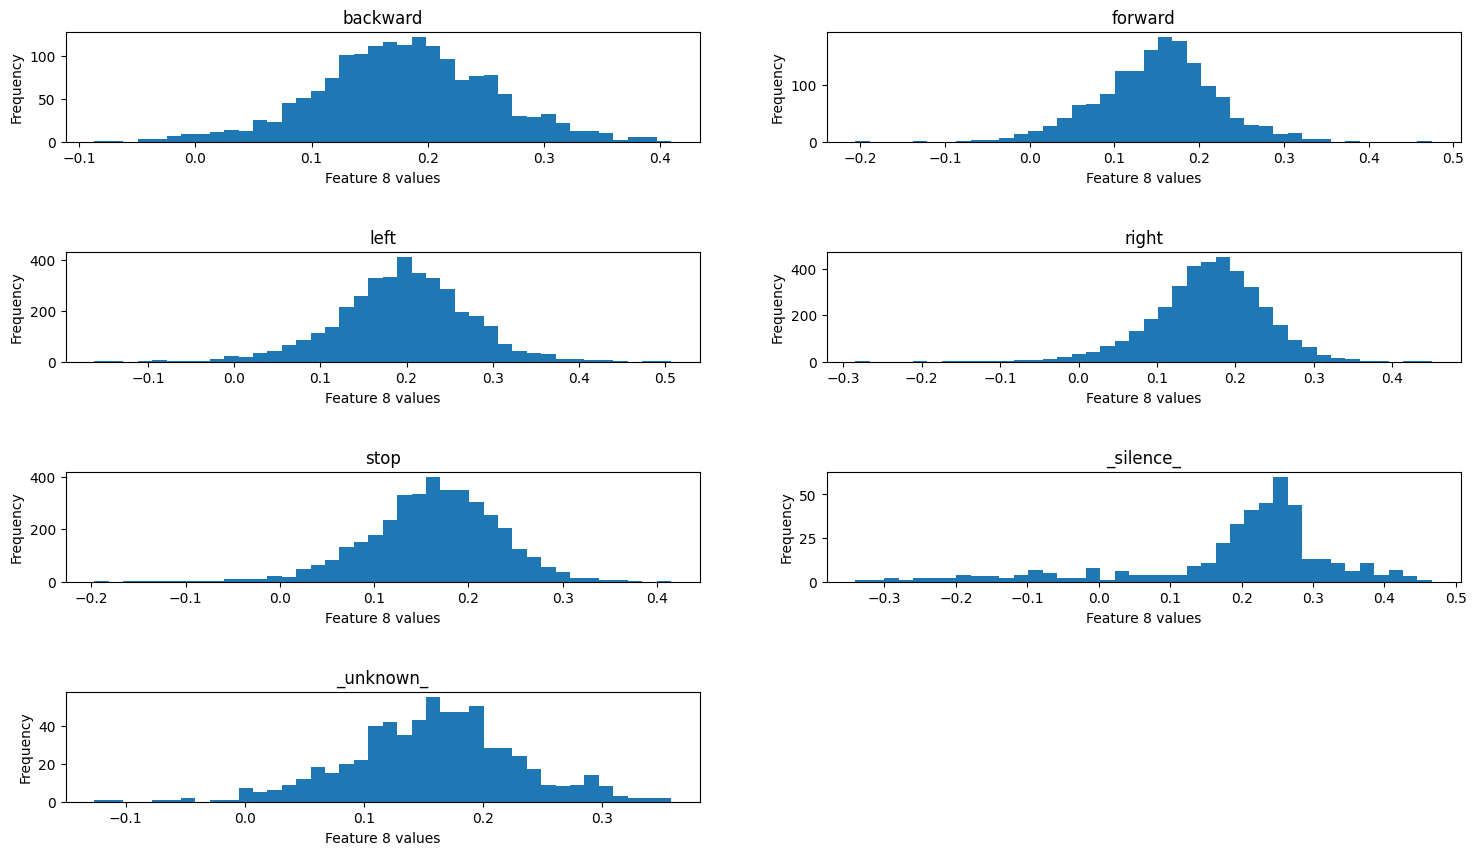

In [57]:
def feature_class_histograms(features: dict, feature: int) -> None:
    ''' Takes in a dictionary with features grouped by class and a mfcc feature number. 
        Plots the feature value distributions for all classes for the given feature. '''
    labels = list(iter(sample_filenames.keys()))
    plt.figure(figsize=(18, 10))

    for i in range(len(labels)):
        data = features[labels[i]].T[feature]

        plt.subplot(4, 2, i+1)
        plt.hist(data, bins=40)
        plt.xlabel(f"Feature {feature} values")
        plt.ylabel("Frequency")
        plt.title(labels[i])
        plt.subplots_adjust(wspace=0.2, hspace=1.0)

feature_class_histograms(mfcc_features, 8)

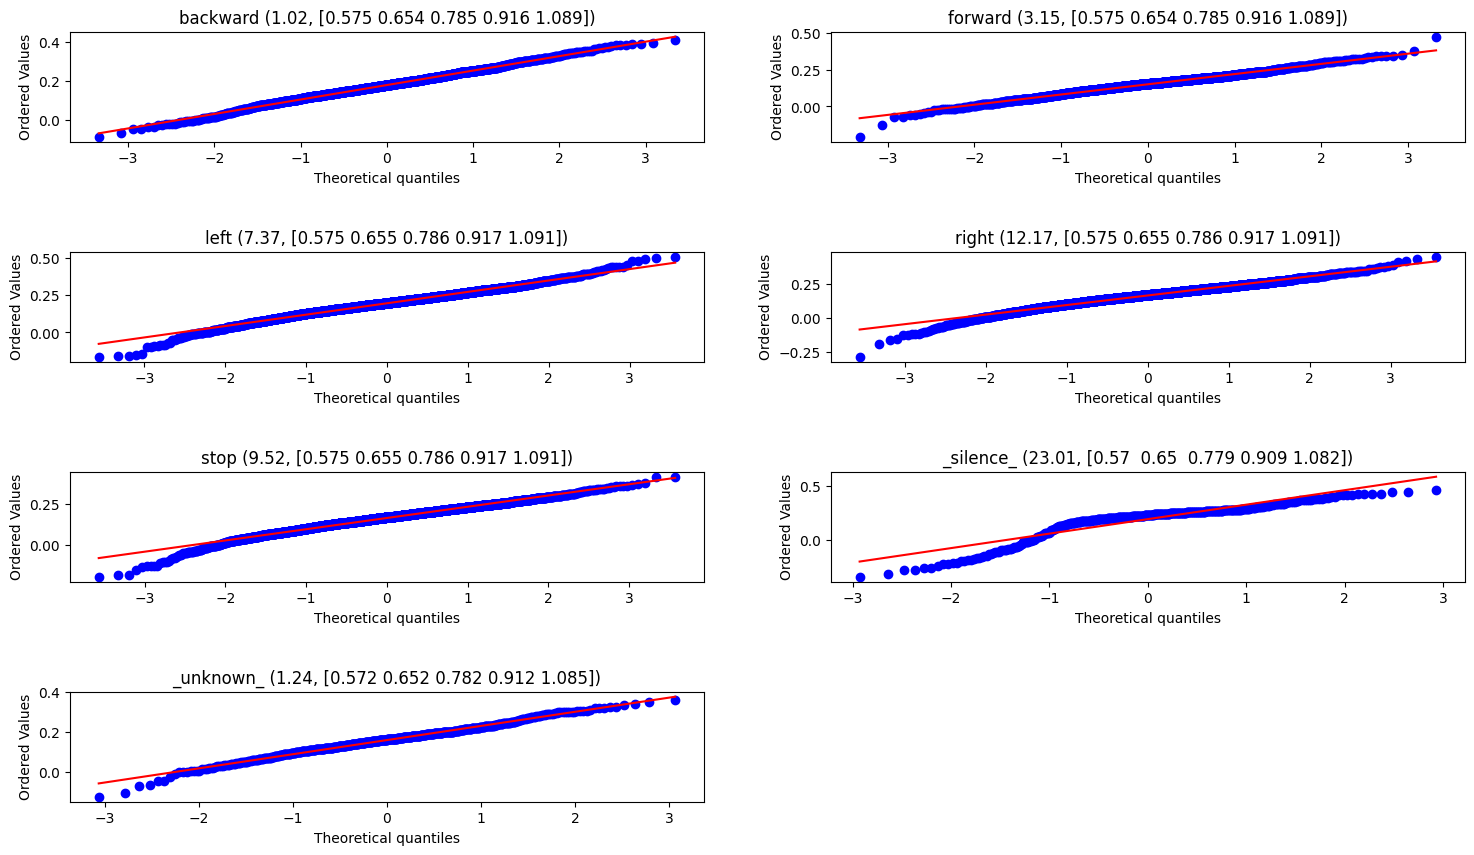

In [58]:
def feature_class_qqplots(features: dict, feature: int) -> None:
    ''' Takes in a dictionary with features grouped by class and a feature number. 
        Plots the QQ plots for all classes for the given feature, while also displaying the statistic and critical values of an Anderson-Darling test. '''
    labels = list(iter(sample_filenames.keys()))
    plt.figure(figsize=(18, 10))

    for i in range(len(labels)):
        data = features[labels[i]].T[feature]

        result = stats.anderson(data)
        plt.subplot(4, 2, i+1)
        stats.probplot(data, dist="norm", plot=plt)
        plt.title(f"{labels[i]} ({result.statistic:.2f}, {result.critical_values})")
        plt.subplots_adjust(wspace=0.2, hspace=1.0)
    plt.show()

feature_class_qqplots(mfcc_features, 8)

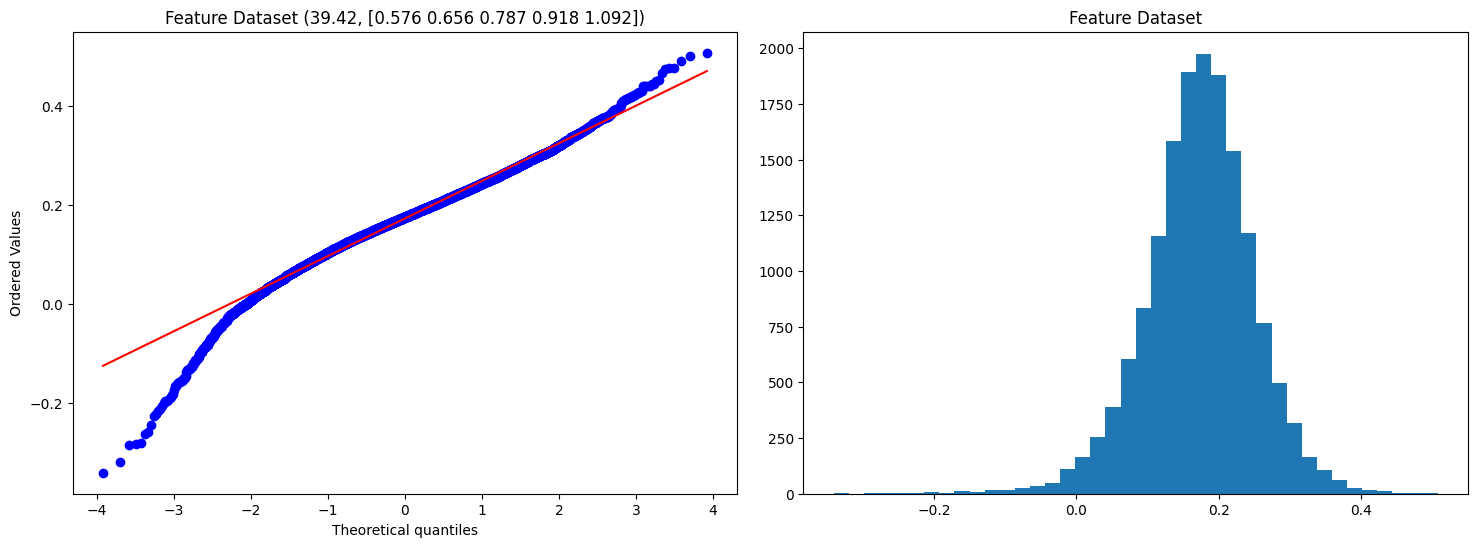

In [59]:
def feature_dataset_plots(features: dict, feature: int, plot_data: bool = True) -> tuple[int, list[int]]:
    ''' Takes in a dictionary with features grouped by class, a feature number and a plot data flag. 
        Plots the QQ plots for the whole feature dataset for the given feature, while also displaying the statistic and critical values of an Anderson-Darling test. '''
    assert 0 <= feature < len(features['forward'][0]), "Feature number must be within the amount of MFCC features"
    labels = list(iter(sample_filenames.keys()))

    data = features[labels[0]].T[feature]
    for i in range(1, len(labels)):
        data = np.concat((data, features[labels[i]].T[feature]))

    result = stats.anderson(data)
    if plot_data:
        plt.figure(figsize=(18, 6))
        plt.subplot(1, 2, 1)
        stats.probplot(data, dist="norm", plot=plt)
        plt.title(f"Feature Dataset ({result.statistic:.2f}, {result.critical_values})")
        plt.subplot(1, 2, 2)
        plt.hist(data, bins=40)
        plt.title("Feature Dataset")
        plt.subplots_adjust(wspace=0.1, hspace=1.0)
        plt.show()
    return (result.statistic, result.critical_values)

_, _ = feature_dataset_plots(mfcc_features, 8)

#### Does the selected feature follow a normal distribution?

No. The above plots show that, to a certain degree, some of the classes show a normal distribution behavior, with histograms displaying a type of bell curve and the QQ plots having some of the datapoints follow the red line (normal distribution). However, once an Anderson-Darling test for normality was conducted (this test was chosen due to unknown mean and variance and large sample sizes), it was revealed that all of the classes don't follow a normal distribution for a significance level of 1%, which leads to the conclusion that the data isn't normally distributed.

**Note**: The values displayed next to the plot titles are the test statistic and critical values, respectively. According to the scipy.stats.anderson documentation, for a normality test, the critical values correspond to the following significance levels: 15%, 10%, 5%, 2.5%, 1%.

#### Ex. 5.3.1. Choice of tests

In total, 2 tests were used: Anderson-Darling test and Kruskal-Wallis H-Test.

The Anderson-Darling test was chosen to investigate normality in the feature dataset due to being most effective for larger sample sizes and unknown mean and standard deviation population parameters. In the plots above, a random feature was chosen from the MFCC and both its distribution and QQ-plot were visualized. Since none of the plots showed normality behavior, the features were assumed not to follow a normal distribution (which was further corroborated by the table in 5.3.2.).

Kruskal-Wallis H-Test was chosen because of the results obtained from the Anderson-Darling tests. Kruskal-Wallis H-Test allows for the comparison of distribution between features to ascertain whether features follow a similar distribution (i.e. if their discriminative power is low) or not. This test is best fit when we want to compare more than 2 unpaired groups of samples (50 in this case) that don't follow a normal distribution (which was concluded with Anderson-Darling). Since all features (except for 1) had the null hypothesis rejected in tests with a significance level of 1%, Kruskal-Wallis was the test used for all features.

As an added bonus, Mann-Whitney U rank test was performed on the MFCC, Delta MFCC and Delta-delta MFCC features with the lowest statistic value for the Kruskal-Wallis H-Test. This latest test is similar to Kruskal-Wallis, with the major difference being a comparison between 2 group samples instead of more than 2. The objective of these 3 tests was to observe the similarity of feature value distributions between classes.

#### Ex. 5.3.2.

In [11]:
# Group all features into a single dictionary (separating by class)
all_class_features = {}

for label in labels:
    all_class_features[label] = []
    for i in range(len(mfcc_features[label])):
        all_class_features[label].append(np.concat((mfcc_features[label][i], dmfcc_features[label][i], 
                                              ddmfcc_features[label][i], zcr_features[label][i])))
    all_class_features[label] = np.array(all_class_features[label])
all_class_features['forward'].shape

(1557, 122)

In [60]:
# Perform the Kruskal-Wallis H-test for all 50 features
kruskal_test = stats.kruskal(all_class_features['forward'], all_class_features['backward'], 
                             all_class_features['left'], all_class_features['right'], 
                             all_class_features['stop'], all_class_features['_silence_'],
                             all_class_features['_unknown_'])

anderson_test_stat = []
anderson_test_crit = []
for i in range(len(all_class_features['forward'][0])):
    stat, crit = feature_dataset_plots(all_class_features, i, False)
    anderson_test_stat.append(stat)
    anderson_test_crit.append(crit)

feature_names = np.concat((np.array([f"MFCC Feature {i+1} Mean" for i in range(len(mfcc_features['forward'][0]))]),
                           np.array([f"DMFCC Feature {i+1} Mean" for i in range(len(dmfcc_features['forward'][0]))]),
                           np.array([f"DDMFCC Feature {i+1} Mean" for i in range(len(dmfcc_features['forward'][0]))]),
                           np.array(["ZCR Features Mean", "ZCR Features Std"])))
df = pd.DataFrame({ 
    'Feature': feature_names,
    'Kruskal Stat': kruskal_test.statistic,
    'Kruskal P-value': kruskal_test.pvalue,
    'Anderson Stat': anderson_test_stat,
    'Anderson Critical Values': anderson_test_crit
})

df_sorted = df.sort_values(by='Kruskal Stat', ascending=False)
df_sorted.reset_index(drop=True, inplace=True)
df_sorted

,Feature,Kruskal Stat,Kruskal P-value,Anderson Stat,Anderson Critical Values
0,ZCR Features Std,4817.262542,0.000000e+00,154.433000,"[0.576, 0.656, 0.787, 0.918, 1.092]"
1,MFCC Feature 2 Mean,3465.236705,0.000000e+00,73.914004,"[0.576, 0.656, 0.787, 0.918, 1.092]"
2,MFCC Feature 10 Mean,3323.828925,0.000000e+00,22.622548,"[0.576, 0.656, 0.787, 0.918, 1.092]"
3,ZCR Features Mean,2950.249992,0.000000e+00,97.393226,"[0.576, 0.656, 0.787, 0.918, 1.092]"
4,MFCC Feature 4 Mean,2871.036500,0.000000e+00,11.457609,"[0.576, 0.656, 0.787, 0.918, 1.092]"
5,MFCC Feature 6 Mean,2860.731630,0.000000e+00,16.135400,"[0.576, 0.656, 0.787, 0.918, 1.092]"
6,MFCC Feature 8 Mean,1777.363074,0.000000e+00,9.672980,"[0.576, 0.656, 0.787, 0.918, 1.092]"
7,MFCC Feature 5 Mean,1634.201421,0.000000e+00,33.689363,"[0.576, 0.656, 0.787, 0.918, 1.092]"
8,MFCC Feature 7 Mean,1582.950190,0.000000e+00,72.714748,"[0.576, 0.656, 0.787, 0.918, 1.092]"
9,MFCC Feature 1 Mean,1505.668402,0.000000e+00,1770.414520,"[0.576, 0.656, 0.787, 0.918, 1.092]"


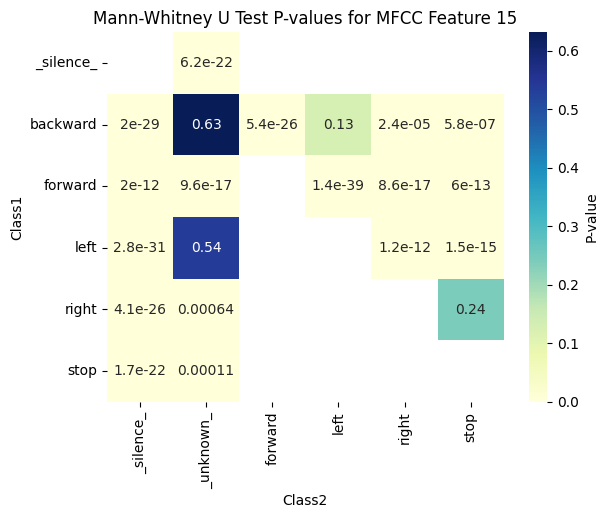

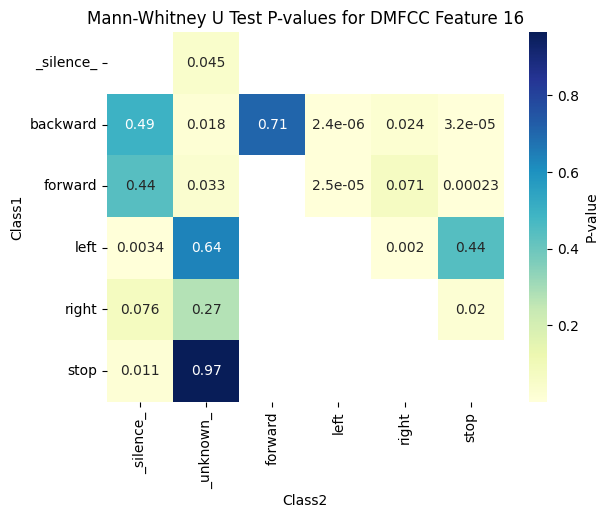

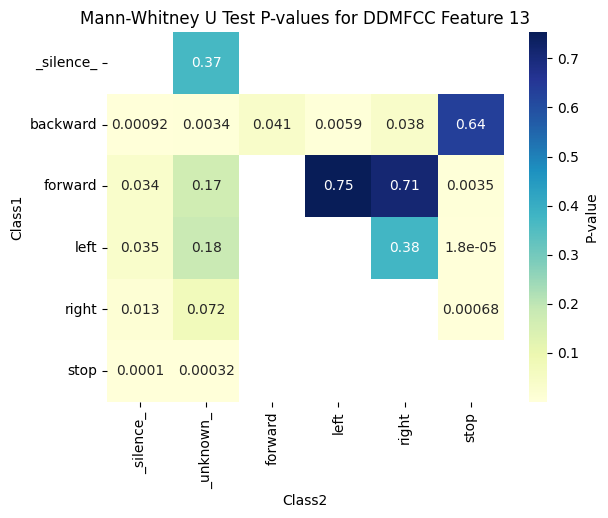

(None, None, None)

In [61]:
def mann_whitney_all(features: dict, feature: int, ft_type: str) -> None:
    ''' Takes in a dictionary with features grouped by class, a feature number and a feature type (MFCC, DMFCC, DDMFCC).
        Performs Mann-Whitney tests for the given feature across all class combinations. '''
    results = []
    for (class1, data1), (class2, data2) in combinations(features.items(), 2):
        data1 = data1.T[feature]
        data2 = data2.T[feature]
        stat, pval = stats.mannwhitneyu(data1, data2, alternative='two-sided')
        results.append({
            "Class1": class1,
            "Class2": class2,
            "Statistic": stat,
            "P-value": pval
        })

    df = pd.DataFrame(results)
    heatmap_data = df.pivot(index="Class1", columns="Class2", values="P-value")
    plt.figure()
    sns.heatmap(heatmap_data, annot=True, cmap='YlGnBu', cbar_kws={'label': 'P-value'})
    plt.title(f"Mann-Whitney U Test P-values for {ft_type} Feature {feature+1}")
    plt.show()

# Mann-Whitney U rank test for the lowest statistic features of MFCC, DMFCC and DDMFCC
mann_whitney_all(mfcc_features, 14, 'MFCC'), mann_whitney_all(dmfcc_features, 15, 'DMFCC'), mann_whitney_all(ddmfcc_features, 12, 'DDMFCC')

## Ex. 6

### Ex. 6.1.

In [101]:
def PCA(X: np.ndarray, threshold: float) -> tuple[np.int64, np.ndarray, np.ndarray]:
    ''' Takes in an array with feature arrays and a cumulative explained variance threshold. 
        Computes the PCA algorithm.
        Returns the number of principal components for the given threshold, along with the feature indices and cumulative explained variance of all features. '''
    # Step 1: Standardize each feature (Z = (X-mean(X))/std(X))
    X_scaled = np.zeros(X.shape)
    for i in range(len(X.T)):
        X_scaled[:, i] = (X.T[i] - np.mean(X.T[i])) / np.std(X.T[i])

    # Step 2: Compute the covariance matrix (for combination(x1, x2) in features: cov(x1, x2))
    X_scaled_cov = np.cov(X_scaled.T)

    # Step 3: Compute eigenvalues and eigenvectors of covariance matrix (cov_mat*X = k*X)
    # Note: Eigenvalues represent the magnitude of variance, eigenvectors represent the principle components (directions)
    # Note 2: The eigenvalue eigval[i] corresponds to the eigenvector eigvec[:, i] and vice-versa
    eigval, eigvec = np.linalg.eig(X_scaled_cov)

    # Step 4: Sort eigenvalues and eigenvectors from highest to lowest (variance)
    idx = eigval.argsort()[::-1]  # Indices of eigenvalues in descending order
    eigval = eigval[idx]
    eigvec = eigvec[:, idx]

    # Step 5: Compute the explained variance (eigval[i] / sum(eigval) -> ratio of variance of eigval[i])
    exp_var = eigval / np.sum(eigval)

    # Step 6: Compute the cumulative explained variance (cum_exp_var[i] = sum(exp_var[:i]) -> total var of first k features)
    cum_exp_var = np.cumsum(exp_var)

    # Step 7: Compute the number of principal components exceeding threshold (cum_exp_var >= threshold)
    # Note: First index of true + 1 indicates number of components within 
    n_comp = np.argmax(cum_exp_var >= threshold) + 1

    return n_comp, idx, cum_exp_var

#### Ex. 6.1.1.

In [102]:
# Unifies all feature arrays separated by class to a single array
all_features = np.concat([all_class_features[label] for label in all_class_features.keys()])
PCA(all_features, 0.75)

(np.int64(24),
 array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 14, 15, 17, 16, 19,
        20, 21, 22, 23, 24, 25, 26, 32, 33, 34, 35, 43, 45, 46, 44, 42, 40,
        41, 39, 38, 37, 36, 31, 30, 29, 28, 27, 18, 13, 12, 48, 49, 47]),
 array([0.09296616, 0.15886163, 0.21345575, 0.26038831, 0.29924964,
        0.33666012, 0.37082428, 0.40161056, 0.43114265, 0.45774895,
        0.48418976, 0.50935878, 0.53326638, 0.55605102, 0.57854127,
        0.60084537, 0.62173539, 0.6419074 , 0.66171915, 0.68027456,
        0.69845496, 0.71642549, 0.73365649, 0.75045483, 0.76649075,
        0.78223306, 0.79739971, 0.81202535, 0.82578027, 0.83918376,
        0.85251593, 0.86513987, 0.87747119, 0.88910991, 0.90062932,
        0.91153391, 0.92200254, 0.93207777, 0.94193947, 0.951092  ,
        0.95987971, 0.9685466 , 0.97706175, 0.98491508, 0.99074194,
        0.99551351, 1.        , 1.        , 1.        , 1.        ]))

##### Interpretation of PCA and its results

PCA essentially determines feature importance by analyzing their variability through the eigenvectors (principal components - PC) and eigenvalues (variance quantification of PCs) of a covariance matrix. Each PC represents a linear combination of the original features, with the first PC (PC1), i.e. the PC with the highest eigenvalue, being the one that captures the direction with most variance/information in the data. PC2 would be the vector with the second highest eigenvalue and orthogonal to PC1, in an attempt to capture the maximum variance in the remaining directions. PC3 would be orthogonal to PC2 and so on. In short, PCA evaluates feature importance/information through variance, with the feature that holds the most variance being the most important.

PCA also defines the concepts of explained variance and cumulative explained variance as the ratio of variance (eigenvalue magnitudes) a feature holds over the entire feature space and the cumulative sum of variance for the top features, respectively. To select the most important features, PCA decides the number of PCs based on a given threshold for the cumulative explained variance which captures the top k features with most (explained) variance.

In this case, a PCA was conducted with a threshold of 75% over the explained variance. The results of the analysis indicated that only 24 of the 50 total features represented 75% of the explained variance in the dataset.

#### Ex. 6.1.2.

In [64]:
# Extracting features selected by PCA
n_comp, idx, _ = PCA(all_features, 0.75)
all_features_pca1 = all_features[:, idx[:n_comp]]
all_features_pca1.shape, all_features_pca1

((15715, 24),
 array([[-3.52235704,  1.58051384,  0.05094877, ...,  0.36397654,
          0.03808336,  0.02338706],
        [-3.44997243,  1.28625005, -0.01250504, ...,  0.00374548,
          0.0083171 , -0.0810655 ],
        [-3.45787719,  1.32023118, -0.07991947, ...,  0.25030705,
          0.16060637,  0.05592244],
        ...,
        [-3.53327487,  1.39058847,  0.31130923, ...,  0.17688127,
          0.16296227, -0.01430749],
        [-3.47367645,  1.35773762,  0.11757496, ..., -0.21564243,
         -0.05436511,  0.1415623 ],
        [-3.60506785,  0.77275694,  0.27558279, ...,  0.05106995,
         -0.13867918,  0.05460563]]))

#### Ex. 6.1.3.

In [65]:
def PCA_feature_reduction(X: np.ndarray, all_features: np.ndarray, threshold: float) -> np.ndarray:
    ''' Takes in a sound's features, the sounds features' dataset and a cumulative variance threshold.
        Returns the PCA tranformation of the given sound's features, according to the given feature dataset and threshold. '''
    _, idx, _ = PCA(all_features, threshold)
    X_reduced = X[idx]    
    return X_reduced

# PCA transformation on the first sound of the sounds features' dataset
PCA_feature_reduction(all_features[0], all_features, 0.75)

array([-3.52235704e+00,  1.58051384e+00,  5.09487702e-02, -6.22812032e-02,
        1.74119309e-01,  3.85935379e-01,  6.18459719e-02,  1.91794647e-01,
        1.83900459e-01,  1.83860767e-01,  1.28049964e-01,  1.18854066e-01,
        1.14604392e-01,  1.47444272e-01,  3.07973428e-01,  3.04786907e-01,
       -5.78407598e-01,  9.58489976e-02, -2.29538351e-01, -4.73892121e-01,
        1.60852649e-01,  3.63976538e-01,  3.80833650e-02,  2.33870576e-02,
        2.87367618e-01, -2.01588974e-01,  1.83830128e-01,  1.97005177e-01,
        8.01109594e-02, -1.30256836e-02, -1.10620419e-01,  3.84389675e-02,
        2.89108485e-02, -1.46884231e-01, -1.22795913e-01, -1.02417544e-01,
       -6.81345354e-02, -1.75874912e-01,  1.04294861e-01,  2.16531575e-01,
        1.79643743e-01,  1.85753042e-01, -9.46174998e-04, -1.47138052e-02,
       -5.79339253e-01,  1.35380121e-01,  1.27386286e-01,  1.42669678e-02,
        2.68068003e-02,  2.13836525e-02])

### Ex. 6.2.

In [ ]:
def fisher_score(X_classes: dict, X: np.ndarray):
    ''' Takes in a dictionary with features grouped by class and a feature dataset as a NumPy array.
        Computes the Fisher Score for each feature and the indices of features ranked in descending order of score. '''
    # Step 1: Compute overall mean of each feature
    X_mean = np.array([np.mean(X.T[i]) for i in range(len(X[0]))])

    # Step 2: Compute mean and variance for each class
    X_classes_mean = {}
    X_classes_var = {}
    for label in X_classes.keys():
        X_classes_mean[label] = np.array([np.mean(X_classes[label].T[i]) for i in range(len(X[0]))])
        X_classes_var[label] = np.array([np.var(X_classes[label].T[i]) for i in range(len(X[0]))])

    # Step 3: Compute inter-class variance (n*(mean(X_classes) - mean(X))**2) and intra-class variance (n*var(X))
    inter_var = {}
    intra_var = {}
    for label in X_classes.keys():
        inter_var[label] = len(X_classes[label])*((X_classes_mean[label] - X_mean)**2)
        intra_var[label] = len(X_classes[label])*X_classes_var[label]

    # Step 4: Compute fisher score for each feature (sum(inter_class)/sum(intra_class))
    inter_var_sum = np.array([np.sum([inter_var[label][i] for label in X_classes.keys()]) for i in range(len(X[0]))])
    intra_var_sum = np.array([np.sum([intra_var[label][i] for label in X_classes.keys()]) for i in range(len(X[0]))])
    fisher_scores = inter_var_sum / intra_var_sum
    idx = fisher_scores.argsort()[::-1]

    return fisher_scores, idx

scores, fisher_idx = fisher_score(all_class_features, all_features)
scores, fisher_idx

(array([0.0487828 , 0.24189476, 0.0834285 , 0.20227858, 0.10694533,
        0.20127138, 0.09681283, 0.11755958, 0.04154761, 0.24626026,
        0.04500896, 0.05290858, 0.01466633, 0.04669843, 0.01183271,
        0.06253604, 0.04503212, 0.02822059, 0.03041614, 0.00411112,
        0.02220494, 0.00475809, 0.00832817, 0.0253335 , 0.01306909,
        0.00449285, 0.00823541, 0.00379785, 0.00506075, 0.00711609,
        0.01152751, 0.00278383, 0.04990604, 0.00573877, 0.00713893,
        0.00685288, 0.00891569, 0.00441896, 0.00559958, 0.00491149,
        0.00475451, 0.00346527, 0.00387889, 0.00359768, 0.00275587,
        0.00551487, 0.00383588, 0.0069614 , 0.32764019, 0.48468094]),
 array([49, 48,  9,  1,  3,  5,  7,  4,  6,  2, 15, 11, 32,  0, 13, 16, 10,
         8, 18, 17, 23, 20, 12, 24, 14, 30, 36, 22, 26, 34, 29, 47, 35, 33,
        38, 45, 28, 39, 21, 40, 25, 37, 19, 42, 46, 27, 43, 41, 31, 44]))

In [104]:
def distance_n(arr1: np.ndarray, arr2: np.ndarray, method: str) -> np.float64:
    ''' Takes in 2 arrays and a distance calculation method.
        Returns the computed distance, based on the calculation method provided. '''
    dist = None
    
    # Manhattan distance - Best for high-dimensional data and robust to outliers
    if method == 'L1':
        dist = np.sum(np.abs(arr1 - arr2))

    # Euclidean distance - Best for low noise and to create spherical clusters
    elif method == 'L2':
        dist = np.linalg.norm(arr1 - arr2)

    else:
        raise Exception("Invalid distance calculation method (use L1 or L2)")
    
    return dist

def diff(feature_idx: int, instance1: np.ndarray, instance2: np.ndarray) -> np.int64:
    ''' Takes in a feature index and 2 feature arrays. 
        Computes the diff function (abs(value(A, I1) - value(A, I2))/(max(A) - min(A)))
        Returns the result of the above described function. '''
    denom = np.abs(instance1[feature_idx] - instance2[feature_idx])
    num = np.max(all_features.T[feature_idx]) - np.min(all_features.T[feature_idx])  # This accesses a global var
    return denom/num

In [109]:
def relieff(X: np.ndarray, y: np.ndarray, m: int, method: str = 'L2') -> np.ndarray:
    ''' Takes in a feature dataset (X) and corresponding features (y), the amount of random instances (m) to select and the measuring distance.
        Computes the ReliefF feature selection algorithm.
        Returns the computed attribute weights. '''
    # Step 1: Initialize the weights array
    weights = np.zeros(len(X[0]))

    # Step 2: Iterate over the random instances
    for i in range(m):
        random_idx = np.random.randint(0, len(X))
        X_random = X[random_idx]
        y_random = y[random_idx]

        # Step 3: Compute distances between random instance and others
        distances = np.array([distance_n(X_random, vec, method) for vec in X])
        distances[random_idx] = float('inf')  # Distance to random instance = infinite
            
        # Step 4: Find nearest miss and nearest hit distances
        sort_idx = distances.argsort()  # Get indices of sorted array
        sorted_labels = y[sort_idx]
        near_hit_idx = sort_idx[np.argmax((sorted_labels == y_random) > 0)]  # Index of nearest hit
        near_miss_idx = sort_idx[np.argmax((sorted_labels == y_random) == 0)]  # Index of nearest miss

        # Step 5: Update weights based on nearest hit and miss, using the diff function
        for f in range(len(weights)):
            weights[f] -= diff(f, X_random, X[near_hit_idx])/m + diff(f, X_random, X[near_miss_idx])/m

    idx = weights.argsort()[::-1]
    return weights, idx

all_labels = np.concat([[label]*len(all_class_features[label]) for label in all_class_features])
weights, relieff_idx = relieff(all_features, all_labels, 10)
weights, relieff_idx

(array([-0.02647705, -0.07213263, -0.1032548 , -0.09804912, -0.14731701,
        -0.16763457, -0.17282144, -0.12982667, -0.15161913, -0.07051412,
        -0.11501274, -0.13225029, -0.15471116, -0.08363074, -0.11348693,
        -0.08954551, -0.06932627, -0.10771961, -0.13178471, -0.15844383,
        -0.14635502, -0.19126736, -0.20355628, -0.13732453, -0.21851214,
        -0.17003433, -0.14034504, -0.15656562, -0.12542632, -0.17347999,
        -0.12695164, -0.14409901, -0.07744449, -0.13309638, -0.17154581,
        -0.14819249, -0.17031903, -0.20337866, -0.22440303, -0.19807224,
        -0.19815239, -0.21169451, -0.10748851, -0.18198578, -0.15048207,
        -0.15868257, -0.15963073, -0.21973728, -0.18982129, -0.26915714]),
 array([ 0, 16,  9,  1, 32, 13, 15,  3,  2, 42, 17, 14, 10, 28, 30,  7, 18,
        11, 33, 23, 26, 31, 20,  4, 35, 44,  8, 12, 27, 19, 45, 46,  5, 25,
        36, 34,  6, 29, 43, 48, 21, 39, 40, 37, 22, 41, 24, 47, 38, 49]))

#### Ex. 6.2.1.

In [69]:
print(f"Top 10 features according to Fisher Score: {fisher_idx[:10]}")
print(f"Top 10 features according to ReliefF: {relieff_idx[:10]}")

Top 10 features according to Fisher Score: [49 48  9  1  3  5  7  4  6  2]
Top 10 features according to ReliefF: [ 0 16  1 32 13 15 17  9 14 12]


##### Differences between Fisher Score and ReliefF

Fisher Score and ReliefF both attempt to rank features based on their importance or how much information they convey. However, the 2 algorithms take different approaches, with Fisher opting to compute the ratio of inter-class and intra-class variance and ReliefF using a nearest neighbors approach to measure how well features differentiate classes through neighboring instances/vectors. Some other differences that can also be observed are:
    
1. Feature evaluation: While Fisher Score attempts to measure a feature's importance without taking others into consideration, ReliefF establishes feature relations (by the use of distance) when computing a feature's importance.
    
2. Complexity: Fisher Score approach is way simpler than ReliefF's, allowing it to have much lower runtimes than ReliefF's. However, ReliefF's complexity allows it to capture more complex relationships between features, something Fisher Score isn't able to do.

#### Ex. 6.2.2.

In [70]:
# Extracting top 10 features according to Fisher's Score
fishers_transformation = all_features[:, fisher_idx[:10]]
fishers_transformation.shape, fishers_transformation

((15715, 10),
 array([[ 0.0268068 ,  0.01426697,  0.18386077, ...,  0.17411931,
          0.06184597,  0.05094877],
        [ 0.02986109,  0.12991333,  0.17843566, ...,  0.12056324,
          0.04482152, -0.01250504],
        [ 0.03945326,  0.13504028,  0.15590042, ...,  0.03687138,
          0.03077046, -0.07991947],
        ...,
        [ 0.02418362,  0.06265259,  0.16902748, ...,  0.10304695,
          0.18763702,  0.31130923],
        [ 0.04178671,  0.09234619,  0.05239018, ...,  0.29730492,
         -0.02644572,  0.11757496],
        [ 0.11645041,  0.1315918 ,  0.20067238, ...,  0.3073618 ,
          0.14008913,  0.27558279]]))

In [71]:
# Extracting top 10 features according to ReliefF
relieff_transformation = all_features[:, relieff_idx[:10]]
relieff_transformation.shape, relieff_transformation

((15715, 10),
 array([[-3.52235704,  0.30478691,  1.58051384, ...,  0.18386077,
          0.11460439,  0.12738629],
        [-3.44997243, -0.56932934,  1.28625005, ...,  0.17843566,
          0.14548575,  0.24664021],
        [-3.45787719, -0.73464675,  1.32023118, ...,  0.15590042,
          0.15617784,  0.2250446 ],
        ...,
        [-3.53327487,  0.03632117,  1.39058847, ...,  0.16902748,
          0.16405537,  0.07629955],
        [-3.47367645, -0.03287635,  1.35773762, ...,  0.05239018,
          0.10548446,  0.20238144],
        [-3.60506785, -0.67513054,  0.77275694, ...,  0.20067238,
          0.14996344,  0.09964627]]))

#### Ex. 6.2.3.

In [72]:
def fisher_relief_reduction(X: np.ndarray, all_features: np.ndarray, all_class_features: dict, method: str, k: int = 10, m: int = 100) -> np.ndarray:
    ''' Takes in a sound's features, the sounds features' dataset, a dictionary with features grouped by class, a method, a top-k integer and a m parameter.
        Returns the transformed (top k) sound's features according to the provided method. '''
    new_X = None

    if method == 'Fisher':
        _, fisher_idx = fisher_score(all_class_features, all_features)
        new_X = X[fisher_idx[:k]]

    elif method == 'ReliefF':
        all_labels = np.concat([[label]*len(all_class_features[label]) for label in all_class_features])
        _, relieff_idx = relieff(all_features, all_labels, m)
        new_X = X[relieff_idx[:k]]
    
    else:
        raise Exception("Invalid feature reduction method (use Fisher or ReliefF)")

    return new_X

fisher_relief_reduction(all_features[0], all_features, all_class_features, 'Fisher')

array([ 0.0268068 ,  0.01426697,  0.18386077,  1.58051384, -0.0622812 ,
        0.38593538,  0.19179465,  0.17411931,  0.06184597,  0.05094877])

### Ex. 6.3. PCA vs Fisher Score vs ReliefF

All 3 algorithms have already had their feature reduction process described in previous sections. As such, this one will focus more on the advantages and disadvantages rather than their different ways of reducing the amount of features.

1. Principal Component Analysis (PCA) - PCA computes the eigenvalues and eigenvectors of a covariance matrix resultant from the feature dataset. The principal components (PC/eigenvectors) are a set of orthogonal axes that attempt to capture the maximum variance in data, with PC1 being the principal component with most variance, PC2 being orthogonal to PC1 and so on. PCA determines the most important features by checking the ones that have the most (highest) explainable variance (eigenvalue) and reduces the feature space by retaining the features below a certain threshold of a cumulative sum of explainable variance. Some of the characteristics of PCA include:

    - Dimensionality Reduction: As it is its main obective, dimensionality reduction can be seen as one of PCA's advantages when presented with high-dimensionality or high redundancy scenarios. However, since PCA relies of variance as the means of evaluating a feature's utlity, some information loss may inevitably occur.

    - Noise and Outliers: By focusing on the directions with most variance, PCA ends up ignoring minor variances produced by the presence of noise in the dataset, making it robust to this data characteristic. However, directions of maximum variance can be inhabited by outliers, which can heavily influence PCA's computations.

    - Interpretability: Since the PCs produced by PCA are linear combinations of the original features, they can be hard to interpret and might have no clear meaning. However, PCA can aid in data interpretation and visualization by projecting high dimensional spaces into more compact ones, helping in pattern finding and clustering.

2. Fisher Score - This algorithm determines feature importance by computing the ration between inter-class variance and intra-class variance and ranks features based on the obtained score. Due to reliance on variance, some characeristics of Fisher Score are similar to those of PCA, namely:

    - Linearity: Both PCA and Fisher Score assume linear relations between the data (variance and mean), which can be good if classes are linearly separable and bad if complex relationships exist between features and classes.

    - Noise and Outliers: Although both algorithms rely on variance (with Fisher also taking mean into consideration), PCA is more robust to noise than Fisher Score, with both algorithms being sensitive to outliers, something that was already discussed on PCA.

    - Feature Independence: The independency assumption makes the algorithm(s) more computationally simple, which, as we've already discussed, can be both a positive and a negative aspect.

3. ReliefF - ReliefF attempts to weight feature importance by measuring how well the features differentiate classes through a nearest neighbors (distance) approach. This algorithm differs from the other 2 in that it doesn't rely on variance and applies more the concept of distance to capture more complex relations. Some of the characteristics of ReliefF include:

    - Complexity: While this algorithm is more computationally complex than the other 2, it, in turn, is able to capture more complex relationships between features and classes, allowing for more complete and rich analysis of feature importance.

    - Dimensionality: Since ReliefF employs a nearest neighbors approach, just like k-Nearest Neighbors, it is very susceptible to performance degradation in high-dimensional spaces (curse of dimensionality).

    - Outlier and Noise: ReliefF's reliance on local data instead of global (like PCA and Fisher Score) and on features that consistently differentiate classes makes it more robust to outliers (than PCA and Fisher Score), noise and redudant features.